# Tổng hợp phát hiện EDA — 20 cổ phiếu HOSE thuộc 7 ngành

Notebook này gom **những phát hiện đắt giá nhất** từ bốn notebook EDA chi tiết (`01`–`04`) thành một mạch đọc liền, cho **20 mã** nhóm theo ngành:
ngân hàng (VCB, BID, CTG, TCB, MBB, STB, VPB), bất động sản (VIC, VHM, NVL, KDH), tiêu dùng (VNM, MSN, SAB, MWG), năng lượng (GAS, PLX), thép (HPG), công nghệ (FPT), chứng khoán (SSI).
Năm mã gốc của giai đoạn đầu (VHM, NVL, STB, VPB, HPG) được đối chiếu với 15 mã mới ở Phát hiện 10.
Mỗi phát hiện gồm: **(1)** ô giải thích — tính gì, công thức, ý nghĩa ký hiệu, các bước; **(2)** ô code; **(3)** hình;
**(4)** phần phân tích ngắn ngay sau hình.

| # | Phát hiện | Hệ quả cho mô hình |
|---|---|---|
| 1 | Dữ liệu VHM trước niêm yết là giá ảo; TCB niêm yết sau mốc đầu khung → khung phân tích chung từ 01/06/2018 | Mọi thống kê dùng chung một khung (T = 2.118 phiên chung đủ 20 mã) |
| 2 | Rủi ro – lợi suất rất khác nhau giữa các mã và các ngành | NVL là ngoại lệ (lỗ, sụt giảm ~91%); ngành quyết định phần lớn khác biệt lợi suất |
| 3 | Lợi suất đuôi dày, không chuẩn ở cả 20 mã | Không dùng giả định chuẩn |
| 4 | Biên độ ±7% **chặn** đuôi phân phối, mức chặn rất khác nhau giữa các mã | Ước lượng đuôi kiểu Hill không dùng trực tiếp được |
| 5 | Biến động cụm mạnh ở cả 20 mã, các đợt biến động cao trùng nhau giữa các ngành | Lọc GARCH trước khi phân tích phụ thuộc |
| 6 | Một nhân tố thị trường chung (43% phương sai) + nhân tố Vingroup/BĐS + nhân tố năng lượng–tiêu dùng | Kiểm soát nhân tố chung và nhân tố ngành khi tìm quan hệ nhân quả |
| 7 | Phụ thuộc đuôi dưới mạnh hơn Gaussian ở 190/190 cặp (184 cặp có CI loại trừ 0); NVL là ngoại lệ | Cần copula/mô hình đuôi, không chỉ tương quan |
| 8 | Không cặp nào trong 380 cặp dẫn–trễ vượt hiệu chỉnh Bonferroni/Holm | Quan hệ chủ yếu là đồng thời |
| 9 | Khối lượng tăng → biến động tăng ở cả 20 mã | Khối lượng là biến giải thích tiềm năng cho biến động |
| 10 | Khác biệt theo ngành; 5 mã gốc biến động cao, bị chặn nhiều hơn 15 mã mới | Diễn giải kết quả theo ngành; so sánh cũ – mới cần tính đến cơ cấu ngành |

**Ký hiệu chung.** $P_{i,t}$: giá đóng cửa (nghìn đồng, đã điều chỉnh) của mã $i$ ở phiên $t$;
lợi suất log $r_{i,t} = \ln(P_{i,t}/P_{i,t-1})$; $T$: số phiên trong khung phân tích; năm có 252 phiên giao dịch.

**Chạy trước:** `python src/build_database.py` (dựng `data/interim/stocks.duckdb`). Hình được lưu thêm vào `report/figure/eda/finding_*.png|pdf`.

## 0. Thiết lập

**Ô này làm gì:** tìm thư mục gốc đồ án, nạp module dùng chung `src/eda_utils.py` (kết nối DuckDB, bảng màu, style hình
theo chuẩn công bố), mở CSDL ở chế độ chỉ đọc và lấy ma trận lợi suất log dạng rộng `r` (mỗi cột một mã) từ view
`v_returns_wide` — view này đã giới hạn sẵn trong khung phân tích chung và bỏ các phiên không có lợi suất.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from scipy.stats import rankdata
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE

r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
start, end = con.execute("SELECT analysis_start, analysis_end FROM analysis_config").fetchone()

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

SC = {**SC, "Công nghệ": PAL["teal"]}      # tách màu Công nghệ khỏi Tiêu dùng (cùng họ xanh lá) khi tô theo ngành
ORIG = U.ORIGINAL_SYMBOLS
iu = np.triu_indices(len(SYMBOLS), 1)
pairs = [(a, b) for k, a in enumerate(SYMBOLS) for b in SYMBOLS[k + 1:]]          # 190 cặp không có hướng
pair_names = [f"{a}–{b}" for a, b in pairs]
same_sector = np.array([SECTOR[a] == SECTOR[b] for a, b in pairs])
print(f"Khung phân tích: {start} → {end} | T = {len(r)} phiên chung × {r.shape[1]} mã ({len(pairs)} cặp: {same_sector.sum()} cùng ngành, {(~same_sector).sum()} khác ngành)")

Khung phân tích: 2018-06-01 → 2026-11-25 | T = 2118 phiên chung × 20 mã (190 cặp: 34 cùng ngành, 156 khác ngành)


## Phát hiện 1 — Giá VHM trước niêm yết là giá ảo; chọn khung phân tích chung

**Tính gì:** với mỗi mã, đếm số phiên trước ngày niêm yết, số phiên khối lượng bằng 0, ngày có dữ liệu đầu tiên;
và lợi suất "ảo" sinh ra nếu tính lợi suất qua mốc niêm yết của VHM.

**Công thức.** Cờ niêm yết $\text{is\_listed}_{i,t} = \mathbb{1}[t \ge t_i^{\text{niêm yết}}]$ và cờ giao dịch
$\text{is\_traded}_{i,t} = \mathbb{1}[V_{i,t} > 0]$ ($V$: khối lượng). Lợi suất chỉ được tính khi phiên liền trước đã niêm yết:

$$r_{i,t} = \begin{cases}\ln(P_{i,t}/P_{i,t-1}) & \text{nếu } t-1 \ge t_i^{\text{niêm yết}}\\ \text{NULL} & \text{ngược lại}\end{cases}$$

**Các bước:** (1) đọc bảng `daily_features` (toàn bộ lịch sử, chưa cắt khung); (2) tổng hợp theo mã bằng SQL;
(3) tính riêng lợi suất qua mốc 16→17/05/2018 của VHM để thấy độ lớn sai số nếu không xử lý;
(4) vẽ dải thời gian có dữ liệu thật của từng mã, đánh dấu ngày bắt đầu khung phân tích.

Nếu không xử lý: lợi suất log VHM ngày 17/05/2018 = ln(30.99/8.41) = 1.30  (≈ 268% trong một phiên)


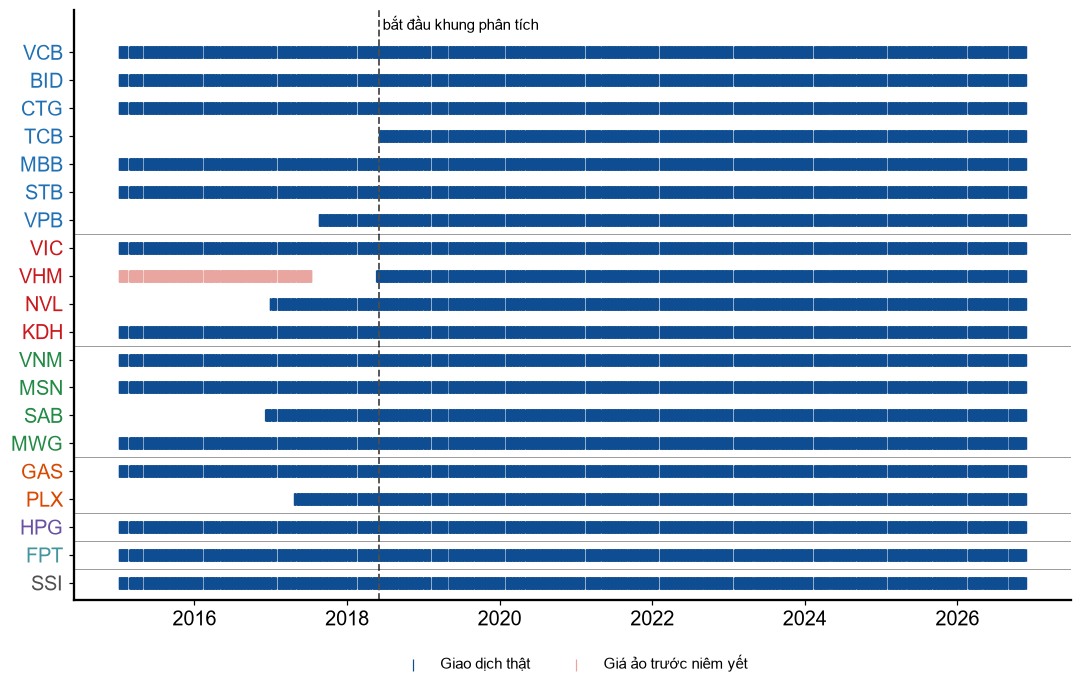

,ngành,ngay_dau_du_lieu,ngay_niem_yet,phien_chua_niem_yet,phien_KL_bang_0
symbol,,,,,
VCB,Ngân hàng,2015-01-05,2015-01-05,0,2
BID,Ngân hàng,2015-01-05,2015-01-05,0,2
CTG,Ngân hàng,2015-01-05,2015-01-05,0,2
TCB,Ngân hàng,2018-06-04,2018-06-04,0,0
MBB,Ngân hàng,2015-01-05,2015-01-05,0,2
STB,Ngân hàng,2015-01-05,2015-01-05,0,2
VPB,Ngân hàng,2017-08-17,2017-08-17,0,2
VIC,Bất động sản,2015-01-05,2015-01-05,0,2
VHM,Bất động sản,2015-01-05,2018-05-17,629,578


In [2]:
profile = con.execute("""
    SELECT f.symbol,
           MIN(f.time)                                   AS ngay_dau_du_lieu,
           MIN(f.time) FILTER (WHERE f.is_listed)        AS ngay_niem_yet,
           SUM((NOT f.is_listed)::INT)                   AS phien_chua_niem_yet,
           SUM((NOT f.is_traded)::INT)                   AS phien_KL_bang_0
    FROM daily_features f GROUP BY f.symbol""").df().set_index("symbol").loc[SYMBOLS].astype(
        {"phien_chua_niem_yet": int, "phien_KL_bang_0": int})
profile.insert(0, "ngành", [SECTOR[s] for s in profile.index])

p_before, p_after = con.execute("""
    SELECT LAG(close) OVER (ORDER BY time), close FROM ohlcv WHERE symbol = 'VHM'
    QUALIFY time = DATE '2018-05-17'""").fetchone()
print(f"Nếu không xử lý: lợi suất log VHM ngày 17/05/2018 = ln({p_after}/{p_before}) = {np.log(p_after/p_before):.2f}"
      f"  (≈ {np.exp(np.log(p_after/p_before))-1:.0%} trong một phiên)")

f = con.execute("SELECT symbol, time, is_listed, is_traded FROM daily_features").df()
fig, ax = plt.subplots(figsize=(10, 6.4))
for y, s in enumerate(SYMBOLS):
    d = f[f.symbol == s]
    ok, fake = d[d.is_listed & d.is_traded], d[~d.is_listed]
    ax.scatter(ok.time, np.full(len(ok), y), marker="|", s=55, color=PAL["blue_main"], lw=0.8,
               label="Giao dịch thật" if y == 0 else None)
    ax.scatter(fake.time, np.full(len(fake), y), marker="|", s=55, color=PAL["red_2"], lw=0.8,
               label="Giá ảo trước niêm yết" if len(fake) else None)
ax.axvline(pd.Timestamp(start), color=PAL["gray_dark"], ls="--", lw=1.2)
ax.text(pd.Timestamp(start), -1.0, " bắt đầu khung phân tích", fontsize=10, va="center")
ax.set_yticks(range(len(SYMBOLS)), SYMBOLS)
for t, s in zip(ax.get_yticklabels(), SYMBOLS): t.set_color(SC[SECTOR[s]])
for i in range(1, len(SYMBOLS)):
    if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: ax.axhline(i - 0.5, color="black", lw=0.5, alpha=0.5)
ax.set_ylim(len(SYMBOLS) - 0.4, -1.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=10)
U.finalize_figure(fig, "finding_1_coverage"); plt.show()
profile

### Phân tích

- VHM có **629 phiên** (01/2015 → 16/05/2018) giá đứng yên 8,41 (578 phiên có khối lượng bằng 0) — đây không phải giao dịch thật trên HOSE. Nếu tính lợi suất qua mốc niêm yết, ta được lợi suất log **1,30 (≈ +268% trong một phiên)** —
  một ngoại lai đủ lớn để làm sai lệch trung bình, độ lệch chuẩn, độ nhọn và biến động 20 phiên.
- 19 mã còn lại không có phiên nào trước niêm yết trong dữ liệu, nhưng nhiều mã bắt đầu muộn hơn 2015: SAB 06/12/2016, NVL 28/12/2016, PLX 21/04/2017, VPB 17/08/2017 và **TCB 04/06/2018** (sau mốc 01/06/2018 hai phiên, nên TCB thiếu 2 phiên đầu khung).
  19 mã (trừ TCB) đều có đúng 2 phiên khối lượng bằng 0 (23–24/01/2018), nằm trước khung phân tích.
- **Quyết định:** dùng khung chung **01/06/2018 → 25/11/2026**: 2.120 phiên cho mỗi mã (TCB 2.118), và **T = 2.118 phiên chung** khi cần ma trận đủ 20 mã (tương quan, PCA, Granger, phụ thuộc đuôi).
  Lợi suất của phiên có phiên liền trước chưa niêm yết được đặt NULL ngay trong SQL nên không thể rò vào các phân tích sau.

## Phát hiện 2 — Rủi ro và lợi suất khác biệt lớn giữa các mã

**Tính gì:** lợi suất năm hoá, biến động năm hoá, tỷ số Sharpe và mức sụt giảm lớn nhất (max drawdown) của từng mã.

**Công thức.**

- Lợi suất trung bình năm hoá: $\hat\mu_i^{\text{năm}} = 252\cdot\bar r_i$, với $\bar r_i = \frac1T\sum_t r_{i,t}$ — vì lợi suất log cộng được theo thời gian.
- Biến động năm hoá: $\hat\sigma_i^{\text{năm}} = \sqrt{252}\cdot s_i$, với $s_i$ là độ lệch chuẩn mẫu của $r_{i,t}$ (giả định lợi suất ngày gần độc lập nên phương sai cộng theo số phiên).
- Sharpe (lãi suất phi rủi ro = 0): $SR_i = \hat\mu_i^{\text{năm}} / \hat\sigma_i^{\text{năm}}$ — lợi suất nhận được trên mỗi đơn vị rủi ro.
- Drawdown: với giá trị tài sản $W_{i,t} = \exp\big(\sum_{s\le t} r_{i,s}\big)$, $DD_{i,t} = W_{i,t}/\max_{s\le t}W_{i,s} - 1$; $MDD_i = \min_t DD_{i,t}$ — mức lỗ tệ nhất từ một đỉnh cũ.

**Các bước:** (1) tính bốn chỉ số trên `r`; (2) chuẩn hoá giá về 100 ở phiên đầu khung để so sánh trên cùng thang (log);
(3) vẽ bản đồ rủi ro – lợi suất cho 20 mã, kích thước điểm tỷ lệ với $|MDD|$, màu theo ngành.

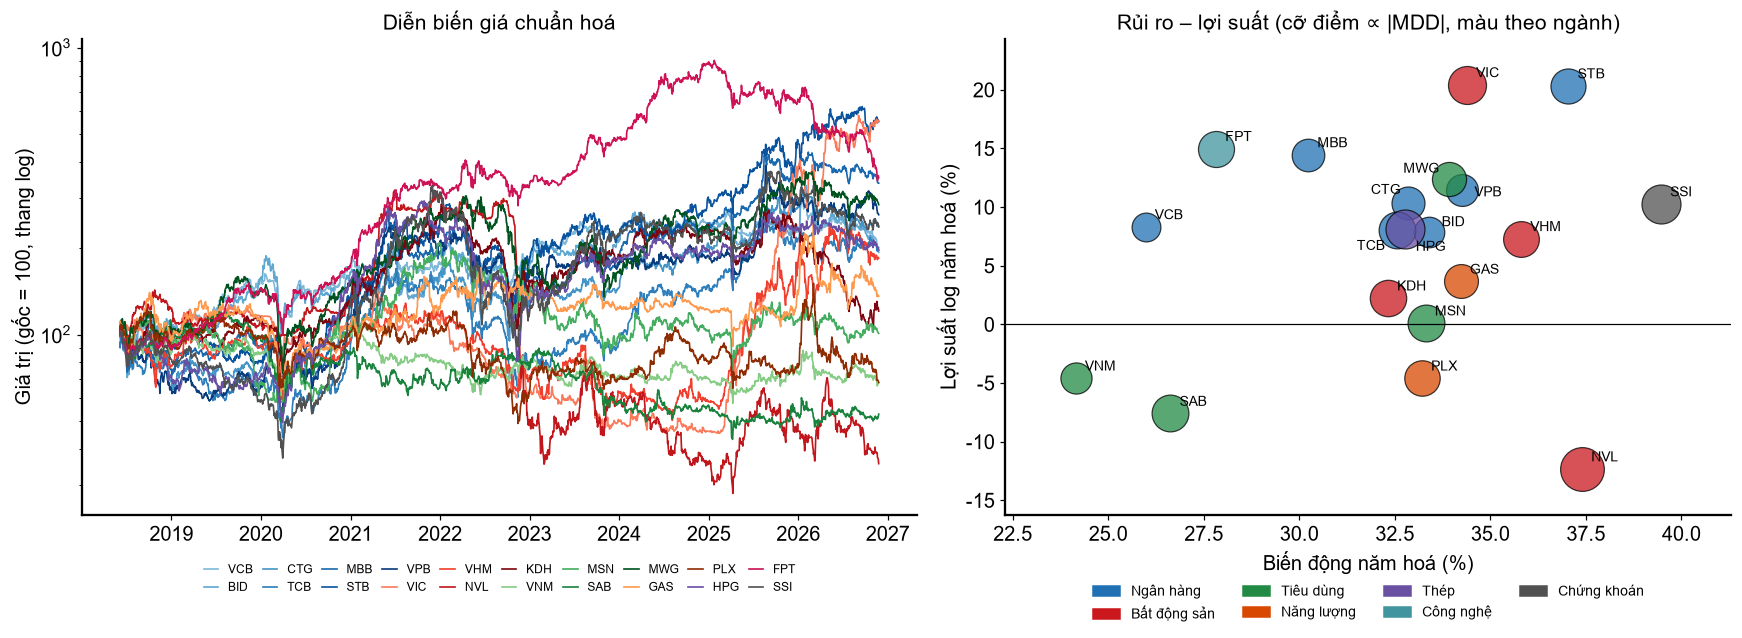

,ngành,mu_nam,sigma_nam,MDD,ngay_day,Sharpe
VCB,Ngân hàng,0.0832,0.2598,-0.3949,2020-03-23,0.3202
BID,Ngân hàng,0.0785,0.3341,-0.4450,2020-03-23,0.2351
CTG,Ngân hàng,0.1034,0.3283,-0.5187,2022-10-11,0.3150
TCB,Ngân hàng,0.0804,0.3254,-0.6434,2022-11-15,0.2471
MBB,Ngân hàng,0.1446,0.3023,-0.5064,2022-11-15,0.4782
STB,Ngân hàng,0.2033,0.3704,-0.5858,2022-10-24,0.5488
VPB,Ngân hàng,0.1144,0.3426,-0.4851,2020-03-31,0.3340
VIC,Bất động sản,0.2043,0.3439,-0.6883,2025-02-12,0.5940
VHM,Bất động sản,0.0730,0.3580,-0.6099,2024-08-05,0.2040
NVL,Bất động sản,-0.1233,0.3740,-0.9123,2025-04-09,-0.3296


In [3]:
W = np.exp(r.cumsum())
dd = W / W.cummax() - 1
summary = pd.DataFrame({
    "ngành": [SECTOR[s] for s in SYMBOLS],
    "mu_nam": 252 * r.mean(),
    "sigma_nam": np.sqrt(252) * r.std(),
    "MDD": dd.min(),
    "ngay_day": dd.idxmin().dt.date,
}, index=SYMBOLS)
summary["Sharpe"] = summary.mu_nam / summary.sigma_nam

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.15, 1]})
for s in SYMBOLS:
    axes[0].plot(W.index, 100 * W[s], color=COL[s], lw=1.1, label=s)
axes[0].set_yscale("log"); axes[0].set_ylabel("Giá trị (gốc = 100, thang log)")
axes[0].set_title("Diễn biến giá chuẩn hoá")
axes[0].legend(ncol=10, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), columnspacing=0.8, handlelength=1.2)
for s in SYMBOLS:
    row = summary.loc[s]
    axes[1].scatter(100 * row.sigma_nam, 100 * row.mu_nam, s=900 * abs(row.MDD), color=SC[SECTOR[s]],
                    alpha=0.75, edgecolor="black", lw=0.8)
    off = {"TCB": (-26, -13), "HPG": (7, -14), "BID": (8, 4), "CTG": (-24, 6), "MWG": (-30, 4), "VPB": (8, -4)}.get(s, (6, 5))
    axes[1].annotate(s, (100 * row.sigma_nam, 100 * row.mu_nam), xytext=off, textcoords="offset points", fontsize=9)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("Biến động năm hoá (%)"); axes[1].set_ylabel("Lợi suất log năm hoá (%)")
axes[1].set_title("Rủi ro – lợi suất (cỡ điểm ∝ |MDD|, màu theo ngành)")
axes[1].margins(0.12)
sector_legend(axes[1], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)
U.finalize_figure(fig, "finding_2_risk_return"); plt.show()
summary

### Phân tích

- **Lợi suất:** cao nhất ở **VIC (+20,4%/năm, Sharpe 0,59)** và **STB (+20,3%, Sharpe 0,55)**, tiếp theo FPT (+15,0%, Sharpe 0,54) và MBB (+14,5%). Âm ở **NVL (−12,3%/năm)**, SAB (−7,6%), VNM (−4,6%), PLX (−4,6%).
  NVL cũng có sụt giảm tối đa sâu nhất, **−91,2%** (đáy 09/04/2025), sau cú sập cuối 2022 — trên hình giá NVL rơi thẳng đứng quanh 11/2022 và không hồi phục.
- **Biến động năm hoá khá hẹp: 24–39,5%** (thấp nhất VNM 24,2% và VCB 26,0%; cao nhất SSI 39,5%, NVL 37,4%, STB 37,0%) trong khi lợi suất trải từ −12% đến +20% → biến động không giải thích được chênh lệch lợi suất.
  Rủi ro đuôi (MDD) phân biệt các mã tốt hơn: nặng nhất NVL (−91%), SSI (−72,5%), HPG (−72,4%), VIC (−68,8%); nhẹ nhất VCB (−39,5%) và BID (−44,5%), hai mã ngân hàng quốc doanh đều có đáy 23/03/2020.
- **Theo ngành** (xem Phát hiện 10): tăng mạnh nhất là công nghệ và ngân hàng; tiêu dùng và năng lượng gần như đi ngang hoặc âm; bất động sản có lợi suất trung bình thấp vì NVL kéo xuống dù VIC tăng mạnh.
- Nhiều mã chạm đáy trong cùng các đợt (23/03/2020, 10–15/11/2022, 08–09/04/2025) → gợi ý nhân tố chung (Phát hiện 6). Riêng FPT có đáy sụt giảm ở ngày 20/11/2026, tức đang trong một đợt giảm mạnh ở cuối mẫu.

## Phát hiện 3 — Lợi suất đuôi dày, không tuân theo phân phối chuẩn

**Tính gì:** độ nhọn vượt chuẩn, kiểm định Jarque–Bera, bậc tự do của phân phối Student-t khớp với dữ liệu, tỷ lệ phiên
đứng giá; và so sánh mật độ thực nghiệm với chuẩn và Student-t trên **thang log** (để nhìn rõ phần đuôi).

**Công thức.**

- Độ lệch $S = \frac{1}{T}\sum_t z_t^3$, độ nhọn vượt chuẩn $K = \frac{1}{T}\sum_t z_t^4 - 3$ với $z_t = (r_t-\bar r)/s$. Phân phối chuẩn có $S = 0, K = 0$; $K > 0$ nghĩa là đỉnh nhọn hơn và đuôi dày hơn chuẩn.
- Jarque–Bera: $JB = \frac{T}{6}\left(S^2 + \frac{K^2}{4}\right) \sim \chi^2_2$ dưới giả thuyết $H_0$: phân phối chuẩn. $JB$ lớn → bác bỏ tính chuẩn.
- Student-t vị trí–thang đo: $f(x) = \frac{\Gamma(\frac{\nu+1}{2})}{\Gamma(\frac{\nu}{2})\sqrt{\nu\pi}\,\sigma}\left(1+\frac{1}{\nu}\left(\frac{x-\mu}{\sigma}\right)^2\right)^{-\frac{\nu+1}{2}}$. Bậc tự do $\nu$ càng nhỏ thì đuôi càng dày ($\nu\to\infty$ trở về chuẩn); ước lượng $(\nu,\mu,\sigma)$ bằng hợp lý cực đại.

**Các bước:** (1) tính $S, K, JB$ và tỷ lệ $r_t = 0$ cho từng mã; (2) khớp phân phối chuẩn và Student-t bằng MLE;
(3) vẽ mật độ thực nghiệm (histogram 60 ô) với trục tung logarit, chồng hai mật độ lý thuyết lên.

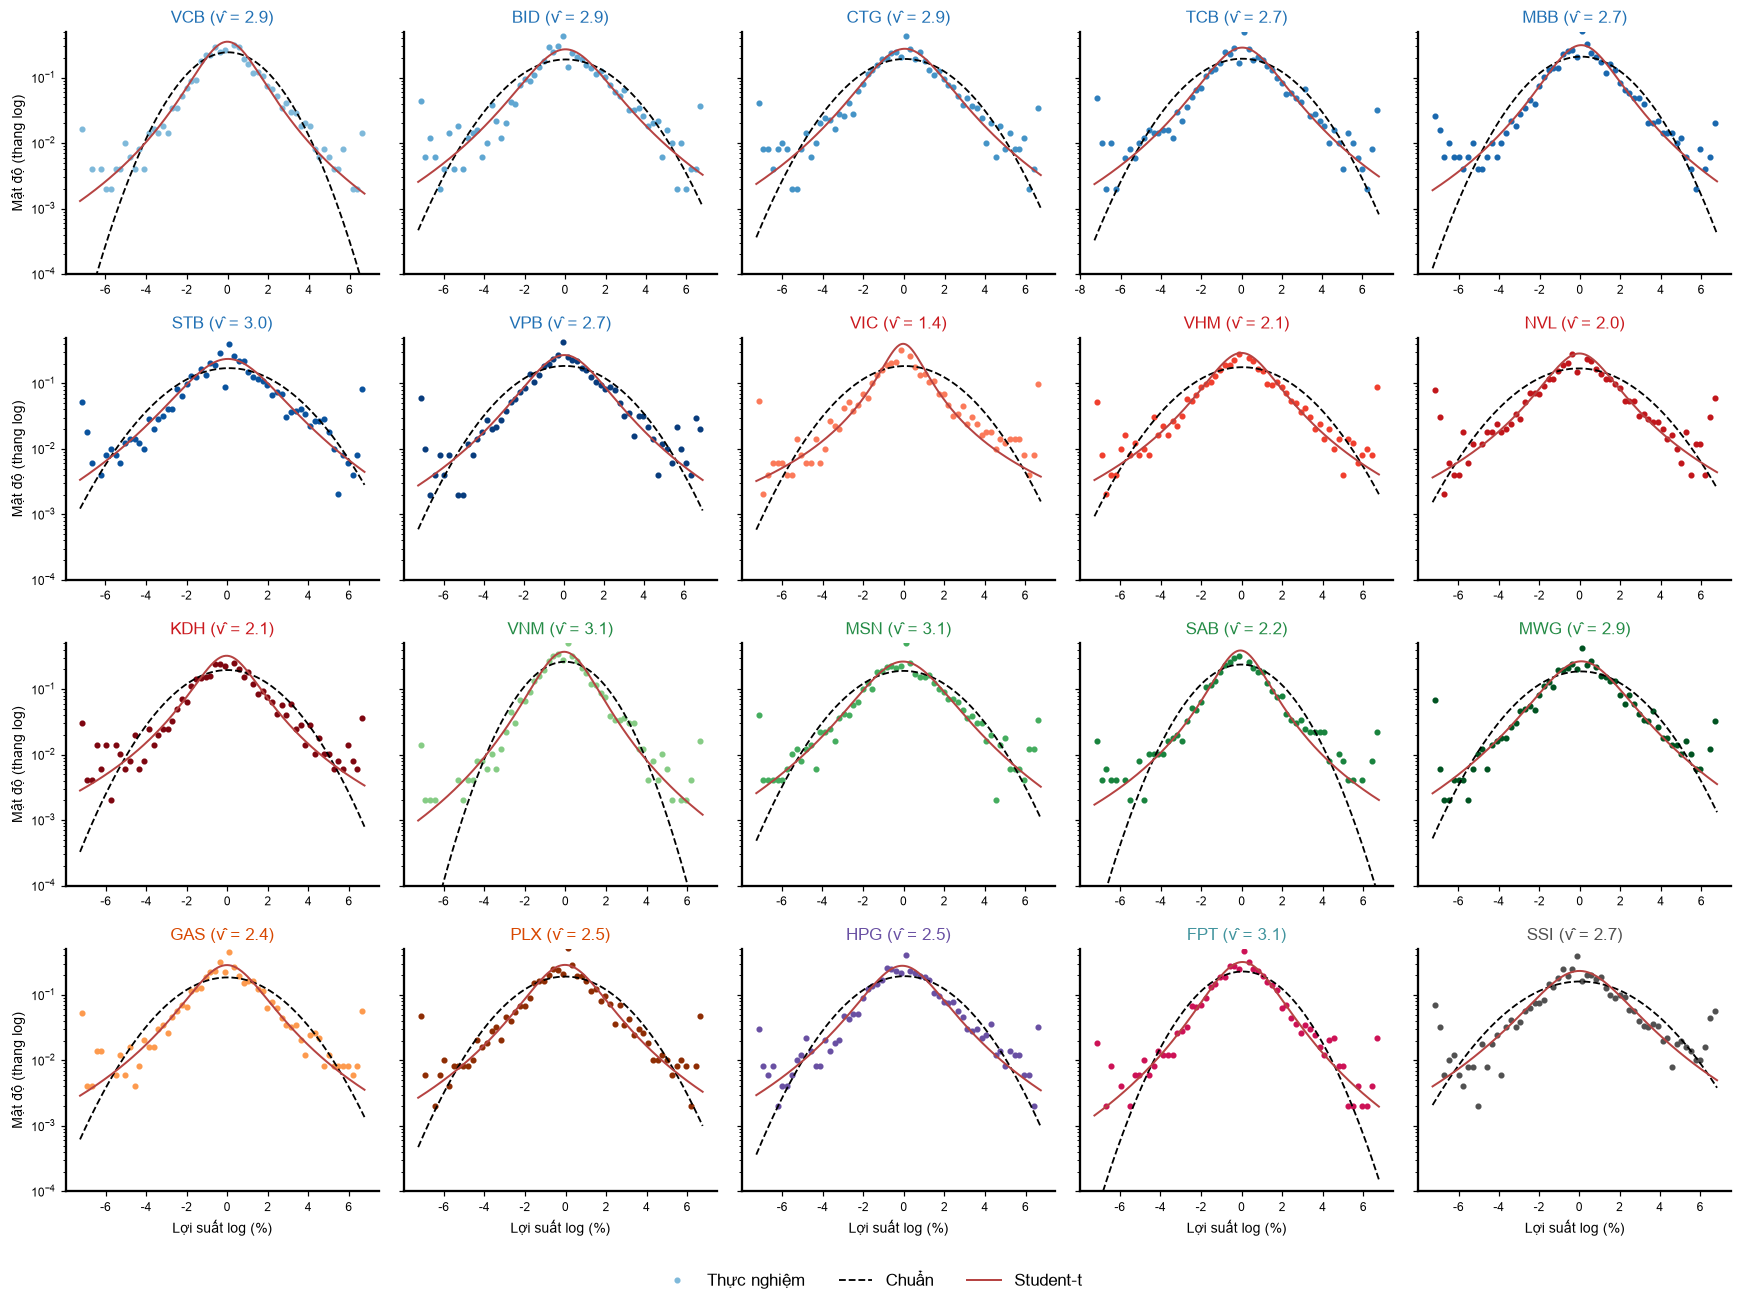

Số mã JB p < 0,001: 20 / 20


,S (độ lệch),K (độ nhọn vượt chuẩn),JB,JB p-value,ν̂ (Student-t),tỷ lệ r = 0
symbol,,,,,,
VCB,-0.0438,3.3372,983.4922,0.0000,2.8738,0.0836
BID,-0.2331,2.2238,455.6220,0.0000,2.8768,0.0675
CTG,-0.2020,2.3354,495.7297,0.0000,2.8868,0.0609
TCB,-0.2735,2.5642,606.6620,0.0000,2.6933,0.0755
MBB,-0.3453,3.0851,882.0473,0.0000,2.6832,0.0855
STB,-0.0097,1.6280,233.9419,0.0000,3.0245,0.0670
VPB,-0.1472,2.2794,466.1799,0.0000,2.7047,0.0940
VIC,0.1999,2.9677,791.3446,0.0000,1.4332,0.1199
VHM,0.0559,2.2240,437.6187,0.0000,2.0916,0.0911


In [4]:
rows, fits = [], {}
for s in SYMBOLS:
    x = r[s].values
    jb = stats.jarque_bera(x)
    nu, loc, sc = stats.t.fit(x)
    fits[s] = (x.mean(), x.std(ddof=1), nu, loc, sc)
    rows.append({"symbol": s, "S (độ lệch)": stats.skew(x), "K (độ nhọn vượt chuẩn)": stats.kurtosis(x),
                 "JB": jb.statistic, "JB p-value": jb.pvalue, "ν̂ (Student-t)": nu, "tỷ lệ r = 0": np.mean(x == 0)})
shape = pd.DataFrame(rows).set_index("symbol")

fig, axes = plt.subplots(4, 5, figsize=(16, 11.5), sharey=True)
for ax, s in zip(axes.ravel(), SYMBOLS):
    x = r[s].values
    mu, sd, nu, loc, sc = fits[s]
    dens, edges = np.histogram(x, bins=60, density=True)
    mid = (edges[:-1] + edges[1:]) / 2
    ax.semilogy(100 * mid[dens > 0], dens[dens > 0] / 100, "o", ms=3, color=COL[s], label="Thực nghiệm")
    g = np.linspace(x.min(), x.max(), 300)
    ax.semilogy(100 * g, stats.norm.pdf(g, loc=mu, scale=sd) / 100, "--", color="black", lw=1.2, label="Chuẩn")
    ax.semilogy(100 * g, stats.t.pdf(g, nu, loc=loc, scale=sc) / 100, color=PAL["red_strong"], lw=1.3, label="Student-t")
    ax.set_title(f"{s} (ν̂ = {nu:.1f})", fontsize=11, color=SC[SECTOR[s]]); ax.set_ylim(1e-4, 0.5)
    ax.tick_params(labelsize=8)
for ax in axes[-1]: ax.set_xlabel("Lợi suất log (%)", fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("Mật độ (thang log)", fontsize=9)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=11)
U.finalize_figure(fig, "finding_3_fat_tails"); plt.show()
print("Số mã JB p < 0,001:", int((shape["JB p-value"] < 1e-3).sum()), "/ 20")
shape

### Phân tích

- Độ nhọn vượt chuẩn $K = 1{,}5$–$3{,}9 > 0$ ở **cả 20 mã** (thấp nhất SSI 1,54, STB 1,63; cao nhất VNM 3,93, SAB 3,92, VCB 3,34), độ lệch $S$ gần 0 (−0,35 ở MBB đến +0,20 ở VIC); Jarque–Bera $JB = 211$–$1.371$, p ≈ 0 → **bác bỏ tính chuẩn** ở 20/20 mã.
  Các mã có biến động thấp và ổn định (VNM, SAB, VCB) lại có độ nhọn cao nhất: phần lớn phiên rất êm, thỉnh thoảng có cú sốc lớn.
- Bậc tự do Student-t ước lượng $\hat\nu \approx 1{,}4$ (VIC) đến $3{,}1$ (FPT, VNM) — rất nhỏ (với $\nu \le 2$ phương sai lý thuyết là vô hạn, điều không thể với lợi suất bị chặn; VIC có $\hat\nu = 1{,}4$, NVL, KDH, VHM, SAB ≈ 2,0–2,2).
  Đây là dấu hiệu Student-t đang bị kéo bởi hai hiện tượng **không phải đuôi dày thật**: khối xác suất tại 0 (**5,6–12,6% số phiên đứng giá** do bước giá rời rạc; cao nhất KDH 12,6%, VIC 12,0%) làm đỉnh nhọn, và các điểm dồn tại ±7% ở rìa (Phát hiện 4).
  Mã có $\hat\nu$ nhỏ nhất cũng là mã có nhiều phiên đứng giá nhất (VIC, KDH), nhất quán với cách giải thích này.
- Hệ quả: không dùng giả định chuẩn (theo AIC ở notebook 03, Student-t tốt hơn chuẩn ở cả 20 mã); nhưng cũng không nên diễn giải $\hat\nu$ như chỉ số đuôi.

## Phát hiện 4 — Biên độ ±7% của HOSE chặn đuôi phân phối

**Tính gì:** biên chặn lý thuyết của lợi suất log, tỷ lệ phiên đóng cửa ở giá trần/sàn, và độ (bất) ổn định của ước lượng
chỉ số đuôi Hill khi dữ liệu bị chặn.

**Công thức.**

- Giá trong phiên bị giới hạn $0{,}93\,P_{t-1} \le P_t \le 1{,}07\,P_{t-1}$, nên $\ln(0{,}93) \approx -0{,}0726 \le r_t \le \ln(1{,}07) \approx 0{,}0677$
  (lệch nhẹ do giá trần/sàn được làm tròn theo bước giá).
- Phiên **chạm trần**: $r^{\text{đơn}}_t \ge 6{,}5\%$ **và** $P_t = H_t$ (đóng cửa tại giá cao nhất); **chạm sàn**: $r^{\text{đơn}}_t \le -6{,}5\%$ và $P_t = L_t$.
- Ước lượng Hill cho đuôi lỗ: sắp xếp mức lỗ $X = -r > 0$ giảm dần $X_{(1)} \ge X_{(2)} \ge \dots$, với $k$ quan sát lớn nhất
  $$\hat\alpha_k = \left(\frac1k\sum_{j=1}^{k}\ln X_{(j)} - \ln X_{(k+1)}\right)^{-1}.$$
  Nếu đuôi theo luật lũy thừa $P(X > x) \propto x^{-\alpha}$ thì $\hat\alpha_k$ phải **ổn định** theo $k$. Khi nhiều quan sát dồn đúng một mức
  (mức sàn), $\ln X_{(j)} - \ln X_{(k+1)} \approx 0$ nên $\hat\alpha_k$ phình lên rất lớn.

**Các bước:** (1) đếm tỷ lệ phiên chạm trần/sàn trong khung (từ cờ `hit_ceiling`, `hit_floor` của CSDL);
(2) vẽ histogram phần đuôi $|r| > 4\%$ cùng hai vạch biên; (3) tính $\hat\alpha_k$ với $k = 10\ldots 150$ và vẽ theo $k$.

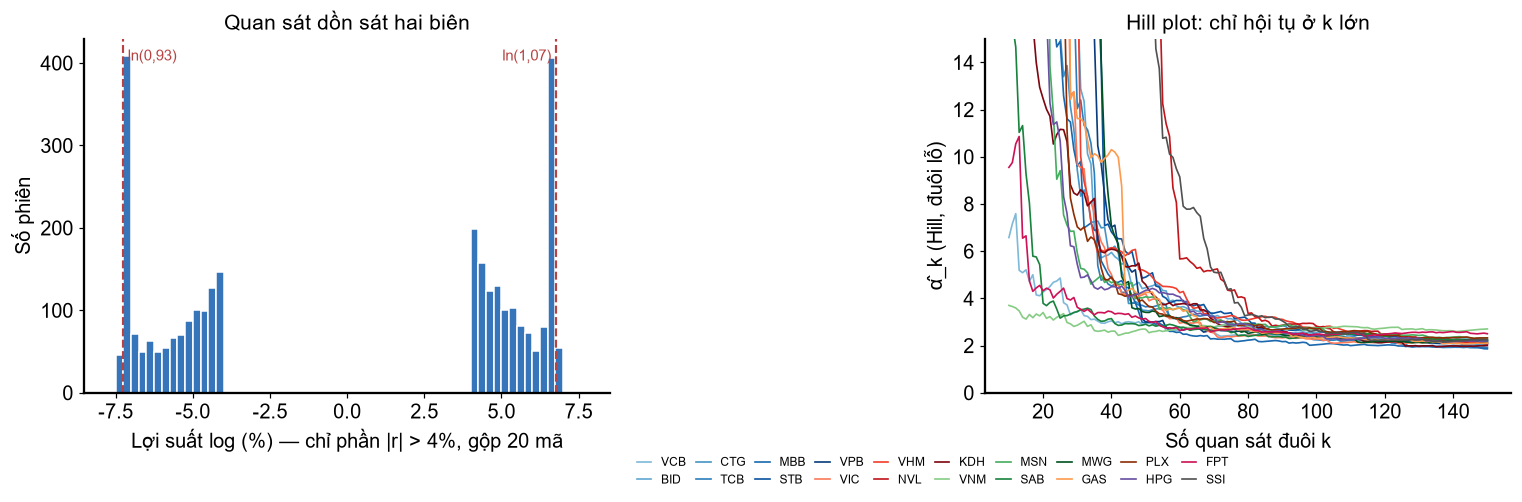

Gộp 20 mã: 318 phiên có r > 6,65% (sát trần), 299 phiên có r < −7,15% (sát sàn) trên 42,360 quan sát
Hill α̂ trung vị: k=25 → 21.1 | k=50 → 3.9 | k=100 → 2.47 (nhỏ nhất–lớn nhất 2.03–2.82)


,ty_le_tran,ty_le_san,α̂ (k=25),α̂ (k=50),α̂ (k=100)
VCB,0.0033,0.0038,4.8622,2.9211,2.3734
BID,0.0094,0.0132,19.6341,4.4543,2.5449
CTG,0.0080,0.0113,15.2421,3.4881,2.4151
TCB,0.0085,0.0127,63.2228,3.6408,2.2456
MBB,0.0057,0.0090,14.8983,2.9777,2.0349
STB,0.0203,0.0160,64.7418,4.8983,2.6856
VPB,0.0118,0.0160,60.3773,3.0016,2.4636
VIC,0.0222,0.0127,90.3756,4.1999,2.2846
VHM,0.0208,0.0142,58.1914,5.1409,2.7828
NVL,0.0208,0.0245,104.0849,28.6082,2.8213


In [5]:
hits = con.execute("""
    SELECT symbol, AVG(hit_ceiling::INT) AS ty_le_tran, AVG(hit_floor::INT) AS ty_le_san
    FROM v_analysis GROUP BY symbol""").df().set_index("symbol").loc[SYMBOLS]
UP, DOWN = np.log(1.07), np.log(0.93)

def hill(losses, ks):
    xs = np.sort(losses[losses > 0])[::-1]
    lx = np.log(xs)
    return np.array([1 / (lx[:k].mean() - lx[k]) for k in ks])

ks = np.arange(10, 151)
hill_curves = {s: hill(-r[s].values, ks) for s in SYMBOLS}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pooled = r.values.ravel()
bins = np.arange(-0.0775, 0.0776, 0.0025)
axes[0].hist(100 * pooled[np.abs(pooled) > 0.04], bins=100 * bins, color=PAL["blue_secondary"], edgecolor="white")
for b, lab in [(UP, "ln(1,07)"), (DOWN, "ln(0,93)")]:
    axes[0].axvline(100 * b, color=PAL["red_strong"], ls="--", lw=1.4)
    axes[0].text(100 * b + (-0.15 if b > 0 else 0.15), axes[0].get_ylim()[1] * 0.97, lab, color=PAL["red_strong"],
                 fontsize=10, ha="right" if b > 0 else "left", va="top")
axes[0].set_xlabel("Lợi suất log (%) — chỉ phần |r| > 4%, gộp 20 mã"); axes[0].set_ylabel("Số phiên")
axes[0].set_title("Quan sát dồn sát hai biên")
for s in SYMBOLS:
    axes[1].plot(ks, hill_curves[s], color=COL[s], lw=1.1, label=s)
axes[1].set_ylim(0, 15); axes[1].set_xlabel("Số quan sát đuôi k"); axes[1].set_ylabel("α̂_k (Hill, đuôi lỗ)")
axes[1].set_title("Hill plot: chỉ hội tụ ở k lớn")
axes[1].legend(ncol=10, fontsize=8, loc="upper center", bbox_to_anchor=(-0.1, -0.15), columnspacing=0.8, handlelength=1.2)
U.finalize_figure(fig, "finding_4_price_limit_censoring"); plt.show()

hill_tab = pd.DataFrame({f"α̂ (k={k})": [hill_curves[s][ks == k][0] for s in SYMBOLS] for k in (25, 50, 100)},
                        index=SYMBOLS)
n_up = int(((pooled > 0.0665)).sum()); n_dn = int((pooled < -0.0715).sum())
print(f"Gộp 20 mã: {n_up} phiên có r > 6,65% (sát trần), {n_dn} phiên có r < −7,15% (sát sàn) trên {len(pooled):,} quan sát")
print("Hill α̂ trung vị: k=25 → %.1f | k=50 → %.1f | k=100 → %.2f (nhỏ nhất–lớn nhất %.2f–%.2f)" % (
    hill_tab.iloc[:, 0].median(), hill_tab.iloc[:, 1].median(), hill_tab.iloc[:, 2].median(), hill_tab.iloc[:, 2].min(), hill_tab.iloc[:, 2].max()))
pd.concat([hits, hill_tab], axis=1)

### Phân tích

- Histogram gộp 20 mã cho thấy hai **cột đột biến ngay tại biên**: ~410 phiên ở ô sát sàn và ~405 phiên ở ô sát trần (trên 42.360 quan sát), trong khi các ô kề bên chỉ khoảng 40–70 phiên ở phía sàn — phân phối không "tắt dần" ra đuôi mà bị **cắt và dồn** tại biên.
  Mức độ bị chặn **rất khác nhau giữa các mã**: tỷ lệ phiên đóng cửa ở giá trần từ 0,28% (VNM) đến 2,31% (SSI) và ở giá sàn từ 0,33% (VNM) đến 2,45% (NVL); các mã bất động sản (VIC, VHM, NVL), SSI, STB chạm biên nhiều nhất; VNM, VCB, SAB, FPT ít nhất (chênh nhau tới ~8 lần).
- Hill plot **không có vùng phẳng ở k nhỏ**: ở k = 25 trung vị α̂ = 21 và có mã lên tới 104 (NVL), 137 (MWG) vì các mức lỗ lớn nhất gần như bằng nhau (cùng mức sàn); ở k = 50 trung vị 3,9 (NVL, SSI vẫn ~28);
  chỉ khi k ≥ 80–100 các đường mới hội tụ về vùng 2–3 (k = 100: 2,03–2,82, trung vị 2,47). Vùng này đã lẫn cả phần thân phân phối, nên α̂ ≈ 2,5 **không thể đọc như chỉ số đuôi thật**; riêng VNM, VCB, SAB, FPT (ít bị chặn) có α̂ ổn định hơn nhiều (k = 25: 3,2–4,9; k = 50: 2,7–3,1).
- Hệ quả: dữ liệu ngày của HOSE là **dữ liệu bị kiểm duyệt (censored)** ở đuôi, mức kiểm duyệt phụ thuộc mã. Phân tích đuôi dày/nhân quả đuôi cần:
  mô hình EVT có kiểm duyệt, hoặc lợi suất tuần (tổng 5 phiên ít bị chặn hơn), hoặc coi phiên trần/sàn là quan sát bị kiểm duyệt.

## Phát hiện 5 — Biến động cụm (volatility clustering)

**Tính gì:** hàm tự tương quan (ACF) của lợi suất $r_t$ và của độ lớn $|r_t|$; kiểm định Ljung–Box; biến động trượt 20 phiên
trung bình của 20 mã (và của từng ngành) theo thời gian.

**Công thức.**

- ACF ở độ trễ $h$: $\hat\rho(h) = \dfrac{\sum_{t=h+1}^{T}(x_t-\bar x)(x_{t-h}-\bar x)}{\sum_{t=1}^{T}(x_t-\bar x)^2}$, áp dụng cho $x_t = r_t$ và $x_t = |r_t|$.
  Dải tin cậy 95% khi không có tự tương quan: $\pm 1{,}96/\sqrt{T}$.
- Ljung–Box: $Q(m) = T(T+2)\sum_{h=1}^{m}\dfrac{\hat\rho(h)^2}{T-h} \sim \chi^2_m$ dưới $H_0$: không tự tương quan đến độ trễ $m$ (dùng $m = 10$).
- Biến động 20 phiên năm hoá: $\hat\sigma_{i,t}^{(20)} = \sqrt{252}\cdot\text{sd}(r_{i,t-19},\dots,r_{i,t})$ (cột `vol_20d` tính sẵn trong CSDL).

**Ý tưởng:** nếu $r_t$ gần như không tự tương quan nhưng $|r_t|$ tự tương quan dương kéo dài, thì **hướng** biến động khó dự báo
nhưng **độ lớn** biến động dự báo được — phiên biến động mạnh có xu hướng đi theo cụm. Đây là dấu hiệu của hiệu ứng ARCH/GARCH.

**Các bước:** (1) tính ACF đến 30 độ trễ cho $r_t$ và $|r_t|$ từng mã; (2) Ljung–Box với $m=10$ cho $r_t$ và $r_t^2$;
(3) lấy `vol_20d` từ CSDL, lấy trung bình 20 mã và từng ngành, đánh dấu đỉnh.

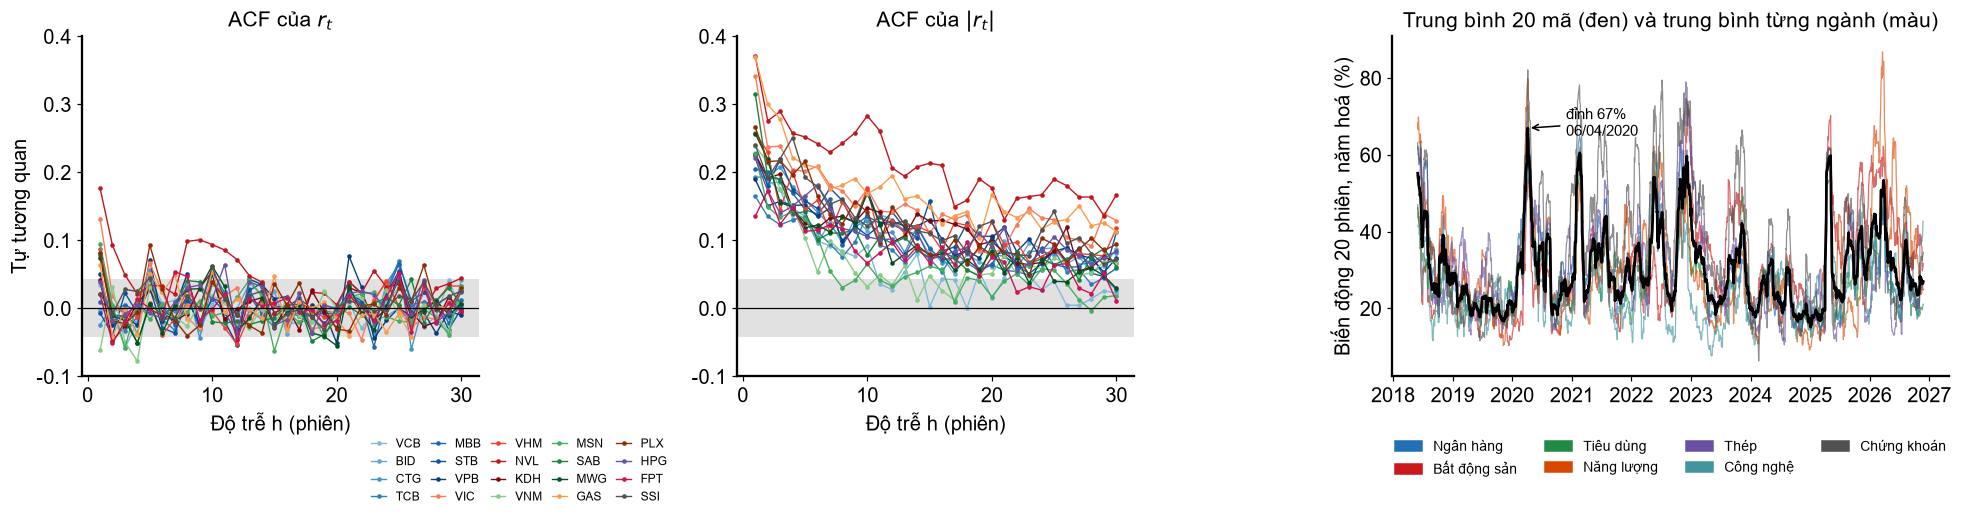

Biến động 20 phiên TB 20 mã: đỉnh 67% (06/04/2020), thấp nhất 15% (03/01/2025)
Q(10) của r có p < 5%: 14 / 20 | Q(10) của r² có p < 1%: 20 / 20
ρ̂(1) của |r|: min 0.14 (FPT), max 0.37 (NVL)


,Q(10) của r: p,Q(10) của r²: p,ρ̂(1) của |r|
VCB,0.0551,0.0000,0.2288
BID,0.1380,0.0000,0.2259
CTG,0.0239,0.0000,0.1930
TCB,0.0008,0.0000,0.1649
MBB,0.7304,0.0000,0.2047
STB,0.2451,0.0000,0.2269
VPB,0.0003,0.0000,0.1897
VIC,0.0000,0.0000,0.3423
VHM,0.0135,0.0000,0.2578
NVL,0.0000,0.0000,0.3713


In [6]:
LAGS = 30
band = 1.96 / np.sqrt(len(r))
vol_s = con.execute("SELECT time, symbol, vol_20d * SQRT(252) AS v FROM v_analysis").df() \
           .pivot(index="time", columns="symbol", values="v")[SYMBOLS]
vol = vol_s.mean(axis=1)                                  # trung bình 20 mã

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for s in SYMBOLS:
    axes[0].plot(range(1, LAGS + 1), acf(r[s], nlags=LAGS)[1:], color=COL[s], lw=0.9, marker="o", ms=2, label=s)
    axes[1].plot(range(1, LAGS + 1), acf(r[s].abs(), nlags=LAGS)[1:], color=COL[s], lw=0.9, marker="o", ms=2)
for ax, t in zip(axes[:2], ["ACF của $r_t$", "ACF của $|r_t|$"]):
    ax.axhspan(-band, band, color=PAL["neutral"], alpha=0.6, lw=0)
    ax.axhline(0, color="black", lw=0.8); ax.set_ylim(-0.1, 0.4)
    ax.set_title(t); ax.set_xlabel("Độ trễ h (phiên)")
axes[0].set_ylabel("Tự tương quan")
axes[0].legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(1.1, -0.15), columnspacing=0.8, handlelength=1.2)
for sec in SECTORS:
    members = [s for s in SYMBOLS if SECTOR[s] == sec]
    axes[2].plot(vol_s.index, 100 * vol_s[members].mean(axis=1), color=SC[sec], lw=0.8, alpha=0.65)
axes[2].plot(vol.index, 100 * vol, color="black", lw=1.8, label="Trung bình 20 mã")
peak = vol.idxmax()
axes[2].annotate(f"đỉnh {100*vol.max():.0f}%\n{peak:%d/%m/%Y}", (peak, 100 * vol.max()), xytext=(25, -5),
                 textcoords="offset points", fontsize=10, arrowprops=dict(arrowstyle="->", lw=1))
axes[2].set_ylabel("Biến động 20 phiên, năm hoá (%)"); axes[2].set_title("Trung bình 20 mã (đen) và trung bình từng ngành (màu)")
sector_legend(axes[2], loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=9)
U.finalize_figure(fig, "finding_5_volatility_clustering"); plt.show()

lb = pd.DataFrame({s: {"Q(10) của r: p": acorr_ljungbox(r[s], lags=[10])["lb_pvalue"].iloc[0],
                       "Q(10) của r²: p": acorr_ljungbox(r[s] ** 2, lags=[10])["lb_pvalue"].iloc[0],
                       "ρ̂(1) của |r|": acf(r[s].abs(), nlags=1)[1]} for s in SYMBOLS}).T
print(f"Biến động 20 phiên TB 20 mã: đỉnh {100*vol.max():.0f}% ({peak:%d/%m/%Y}), thấp nhất {100*vol.min():.0f}% ({vol.idxmin():%d/%m/%Y})")
print("Q(10) của r có p < 5%:", int((lb["Q(10) của r: p"] < .05).sum()), "/ 20 | Q(10) của r² có p < 1%:", int((lb["Q(10) của r²: p"] < .01).sum()), "/ 20")
print("ρ̂(1) của |r|: min %.2f (%s), max %.2f (%s)" % (lb["ρ̂(1) của |r|"].min(), lb["ρ̂(1) của |r|"].idxmin(), lb["ρ̂(1) của |r|"].max(), lb["ρ̂(1) của |r|"].idxmax()))
lb

### Phân tích

- ACF của **$r_t$** gần như nằm trong dải tin cậy: Ljung–Box Q(10) có p < 5% ở 14/20 mã (rất nhỏ ở VIC, NVL, GAS, PLX, VNM, MWG, VPB, TCB: p < 0,001) nhưng biên độ tự tương quan nhỏ; không có ý nghĩa ở MBB (p = 0,73), HPG (0,46), STB (0,25), BID (0,14), và sát ngưỡng ở VCB (0,055), SSI (0,052)
  → **hướng** giá gần như không dự báo được từ quá khứ.
- ACF của **$|r_t|$** dương ở cả 30 độ trễ, $\hat\rho(1)$ từ 0,14 (FPT) đến 0,37 (NVL; cũng cao ở GAS 0,37, VIC 0,34, SAB 0,32); Q(10) của $r_t^2$ có p ≈ 0 ở **20/20 mã** → **độ lớn** biến động có trí nhớ dài.
- Biến động 20 phiên trung bình 20 mã đạt **đỉnh ~67% ngày 06/04/2020** (COVID) và thấp nhất ~15% ngày 03/01/2025; biến động dồn thành từng cụm, và đường trung bình từng ngành (màu) cùng tăng vọt trong các đợt chung (03–04/2020, đầu 2021, 11/2022, 04/2025)
  → cụm biến động mang tính **hệ thống** chứ không chỉ riêng từng mã.
- Hệ quả: các kiểm định và ước lượng phụ thuộc giả định phương sai không đổi sẽ sai → **lọc GARCH** (hoặc dùng sai số chuẩn HAC) trước khi phân tích quan hệ giữa các mã.

## Phát hiện 6 — Một nhân tố thị trường chung, cộng nhân tố riêng của Vingroup/bất động sản và của năng lượng – tiêu dùng

**Tính gì:** ma trận tương quan Pearson giữa lợi suất 20 mã và phân tích thành phần chính (PCA) trên ma trận đó.

**Công thức.**

- Tương quan Pearson: $\rho_{ij} = \dfrac{\sum_t (r_{i,t}-\bar r_i)(r_{j,t}-\bar r_j)}{\sqrt{\sum_t (r_{i,t}-\bar r_i)^2}\sqrt{\sum_t (r_{j,t}-\bar r_j)^2}} \in [-1, 1]$.
- PCA: chuẩn hoá $z_{i,t} = (r_{i,t}-\bar r_i)/s_i$, phân rã ma trận tương quan $\mathbf R = \mathbf V\boldsymbol\Lambda\mathbf V^\top$ với
  $\lambda_1 \ge \dots \ge \lambda_{20}$. Thành phần thứ $k$: $PC_{k,t} = \sum_i v_{ik} z_{i,t}$; tỷ lệ phương sai giải thích $\lambda_k / \sum_j \lambda_j$.
  Hệ số tải $v_{ik}$ cho biết mã $i$ đóng góp bao nhiêu vào thành phần $k$.

**Đọc kết quả:** nếu PC1 có hệ số tải **cùng dấu, gần bằng nhau** ở mọi mã thì PC1 là "nhân tố thị trường" — mọi mã cùng lên
cùng xuống. Các PC sau mô tả phần **riêng** của từng nhóm/mã.

**Các bước:** (1) tính $\mathbf R$; (2) phân rã trị riêng, sắp giảm dần, cố định dấu véc-tơ riêng để tổng hệ số tải dương;
(3) vẽ heatmap tương quan 20×20 (nhãn tô màu theo ngành, vạch đen phân cách ngành), cột phương sai giải thích và heatmap hệ số tải PC1–PC3. So với ngưỡng nhiễu Marchenko–Pastur $\lambda_{\max}=(1+\sqrt{N/T})^2$ ($N=20$ mã, $T$ phiên) để biết có bao nhiêu thành phần chứa tín hiệu thật.

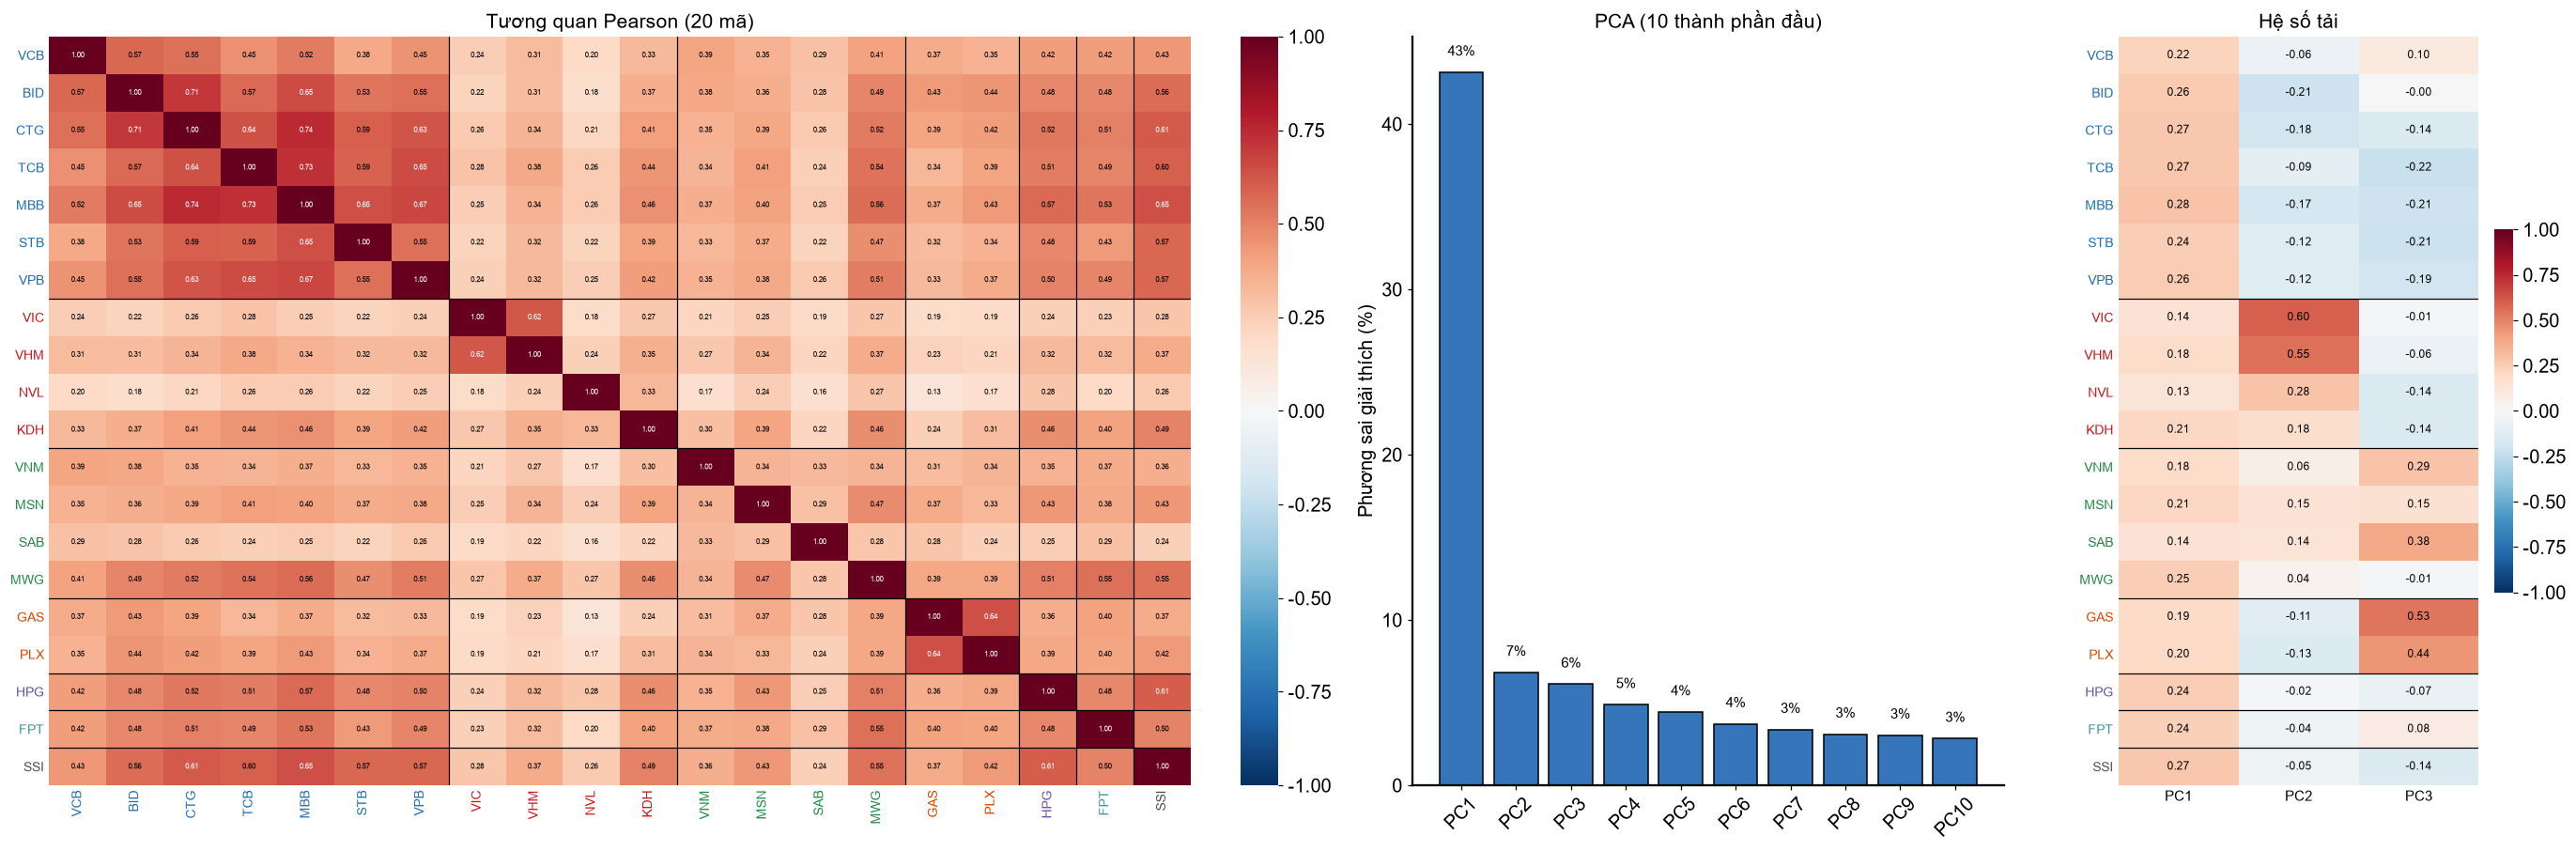

Tương quan 190 cặp: min 0.13 (NVL–GAS) | TB 0.39 | max 0.74 (CTG–MBB)
Cao nhất: {'BID–MBB': 0.65, 'TCB–VPB': 0.65, 'MBB–VPB': 0.67, 'BID–CTG': 0.71, 'TCB–MBB': 0.73, 'CTG–MBB': 0.74}
Thấp nhất: {'NVL–GAS': 0.13, 'NVL–SAB': 0.16, 'NVL–PLX': 0.17, 'NVL–VNM': 0.17, 'BID–NVL': 0.18, 'VIC–NVL': 0.18}
TB cùng ngành 0.502 | khác ngành 0.360
Phương sai giải thích PC1–PC5 (%): [43.1, 6.8, 6.1, 4.9, 4.4] | λ1 = 8.63, ngưỡng MP = 1.20, số trị riêng vượt ngưỡng: 3
PC1: tải nhỏ nhất NVL 0.13 | lớn nhất MBB 0.28
PC2 {'VIC': 0.6, 'VHM': 0.55, 'NVL': 0.28, 'BID': -0.21}
PC3 {'GAS': 0.53, 'PLX': 0.44, 'SAB': 0.38, 'VNM': 0.29}


,PC1,PC2,PC3
VCB,0.2200,-0.0600,0.1000
BID,0.2600,-0.2100,-0.0000
CTG,0.2700,-0.1800,-0.1400
TCB,0.2700,-0.0900,-0.2200
MBB,0.2800,-0.1700,-0.2100
STB,0.2400,-0.1200,-0.2100
VPB,0.2600,-0.1200,-0.1900
VIC,0.1400,0.6000,-0.0100
VHM,0.1800,0.5500,-0.0600
NVL,0.1300,0.2800,-0.1400


In [7]:
R = r.corr()
eigval, eigvec = np.linalg.eigh(R.values)
order = eigval.argsort()[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
eigvec *= np.sign(eigvec.sum(axis=0))
explained = eigval / eigval.sum()
pcs = [f"PC{k+1}" for k in range(len(SYMBOLS))]
loadings = pd.DataFrame(eigvec, index=SYMBOLS, columns=pcs)
mp_max = (1 + np.sqrt(len(SYMBOLS) / len(r))) ** 2           # ngưỡng Marchenko–Pastur của trị riêng nhiễu thuần tuý

fig, axes = plt.subplots(1, 3, figsize=(25, 8.4), gridspec_kw={"width_ratios": [1.9, 0.9, 0.6]})
big_heatmap(axes[0], R, fs_cell=5.5, vmin=-1, vmax=1, title="Tương quan Pearson (20 mã)")
K = 10
axes[1].bar(pcs[:K], 100 * explained[:K], color=PAL["blue_secondary"], edgecolor="black", lw=1)
for k, v in enumerate(explained[:K]):
    axes[1].text(k, 100 * v + 1, f"{100*v:.0f}%", ha="center", fontsize=10)
axes[1].set_ylabel("Phương sai giải thích (%)"); axes[1].set_title(f"PCA ({K} thành phần đầu)")
axes[1].tick_params(axis="x", rotation=45)
U.make_heatmap(axes[2], loadings[pcs[:3]], vmin=-1, vmax=1, title="Hệ số tải")
for t in axes[2].texts: t.set_fontsize(8)
sector_style(axes[2], SYMBOLS, axis="y", sep=False, fs=9)
axes[2].set_xticks(range(3), pcs[:3], rotation=0, fontsize=10)
for i in range(1, len(SYMBOLS)):
    if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: axes[2].axhline(i - 0.5, color="black", lw=0.8)
U.finalize_figure(fig, "finding_6_correlation_pca"); plt.show()

off = pd.Series(R.values[iu], index=pair_names).sort_values()
print("Tương quan 190 cặp: min %.2f (%s) | TB %.2f | max %.2f (%s)" % (off.min(), off.index[0], off.mean(), off.max(), off.index[-1]))
print("Cao nhất:", off.tail(6).round(2).to_dict()); print("Thấp nhất:", off.head(6).round(2).to_dict())
print("TB cùng ngành %.3f | khác ngành %.3f" % (R.values[iu][same_sector].mean(), R.values[iu][~same_sector].mean()))
print("Phương sai giải thích PC1–PC5 (%):", (100 * explained[:5]).round(1).tolist(), "| λ1 = %.2f, ngưỡng MP = %.2f, số trị riêng vượt ngưỡng: %d" % (eigval[0], mp_max, (eigval > mp_max).sum()))
print("PC1: tải nhỏ nhất %s %.2f | lớn nhất %s %.2f" % (loadings.PC1.idxmin(), loadings.PC1.min(), loadings.PC1.idxmax(), loadings.PC1.max()))
for pc in ("PC2", "PC3"):
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, {s: round(float(loadings.loc[s, pc]), 2) for s in top})
pd.concat([loadings[pcs[:3]], pd.DataFrame([explained[:3]], index=["tỷ lệ giải thích"], columns=pcs[:3])]).round(2)

### Phân tích

- Tương quan Pearson của 190 cặp **đều dương**, từ 0,13 đến 0,74 (trung bình 0,39); **cùng ngành trung bình 0,50, khác ngành 0,36**. Cao nhất là nhóm ngân hàng: **CTG–MBB 0,74**, TCB–MBB 0,73, BID–CTG 0,71, MBB–VPB 0,67 (trung bình trong ngành ngân hàng 0,59), và GAS–PLX 0,64, VIC–VHM 0,62.
  **NVL tương quan yếu nhất với hầu hết mã** (NVL–GAS 0,13, NVL–SAB 0,16, NVL–PLX/VNM 0,17), kể cả với VHM (0,24) cùng ngành bất động sản; ngành bất động sản có tương quan trong ngành chỉ 0,33.
- **PC1 giải thích 43,1% phương sai** (λ₁ = 8,63 so với ngưỡng nhiễu Marchenko–Pastur 1,20) với hệ số tải cùng dấu dương ở cả 20 mã (0,13–0,28) → một **nhân tố thị trường** chung; tải lớn nhất ở MBB, SSI, CTG, TCB (0,27–0,28), nhỏ nhất ở NVL (0,13).
  Chỉ 3 trị riêng vượt ngưỡng nhiễu: **PC2 (6,8%) là nhân tố Vingroup/bất động sản** (VIC 0,60, VHM 0,55, NVL 0,28), **PC3 (6,1%) là nhân tố năng lượng – tiêu dùng phòng thủ** (GAS 0,53, PLX 0,44, SAB 0,38, VNM 0,29);
  NVL tách riêng hơn nữa ở PC4. So với mẫu 5 mã trước (PC1 ~49%, PC2 ≈ NVL, PC3 ≈ VHM), nhân tố chung loãng đi khi thêm mã và cấu trúc ngành hiện rõ.
- Hệ quả: quan hệ giữa hai mã bất kỳ một phần là do cùng chịu nhân tố thị trường (và nhân tố ngành). Khi tìm quan hệ nhân quả cần kiểm soát nhân tố chung (ví dụ thêm biến thị trường/PC1) để tránh kết luận giả.

## Phát hiện 7 — Phụ thuộc đuôi dưới mạnh hơn mức phân phối chuẩn cho phép

**Tính gì:** xác suất hai mã **cùng** rơi vào nhóm 5% phiên tệ nhất của chính nó, so với xác suất đó nếu cấu trúc phụ thuộc là
chuẩn (Gaussian copula) có cùng tương quan; kèm khoảng tin cậy bằng bootstrap khối.

**Công thức.**

- Đổi lợi suất sang hạng chuẩn hoá (giả-quan sát copula): $U_{i,t} = \text{rank}(r_{i,t})/(T+1) \in (0,1)$ — loại bỏ ảnh hưởng của phân phối biên, chỉ giữ cấu trúc phụ thuộc.
- Hệ số phụ thuộc đuôi dưới thực nghiệm tại mức $q$:
  $$\hat\lambda_L(q) = \frac{\#\{t : U_{i,t}\le q,\ U_{j,t}\le q\}}{T\,q} \approx P(U_j \le q \mid U_i \le q).$$
  Nếu hai mã độc lập, $\hat\lambda_L(q) \approx q = 0{,}05$; nếu luôn cùng sập, $\hat\lambda_L = 1$.
- Mức tham chiếu Gaussian: $\lambda_{G}(q) = \Phi_2\big(\Phi^{-1}(q), \Phi^{-1}(q); \rho\big)/q$, trong đó $\Phi_2$ là hàm phân phối chuẩn hai chiều
  với tương quan $\rho = 2\sin(\pi\rho_S/6)$ suy từ tương quan hạng Spearman $\rho_S$ (công thức đúng cho Gaussian copula).
- **Bootstrap khối** (giữ cấu trúc biến động cụm): lấy ngẫu nhiên các khối 20 phiên liên tiếp có hoàn lại cho đủ $T$ phiên,
  tính lại $\hat\lambda_L - \lambda_G$; lặp $B = 1.000$ lần, lấy phân vị 2,5% và 97,5% làm khoảng tin cậy 95%.

**Các bước:** (1) tính $U$; (2) với 190 cặp (20 mã), tính $\hat\lambda_L(0{,}05)$ và $\lambda_G$; (3) bootstrap khối;
(4) vẽ heatmap $\hat\lambda_L$ 20×20 và đồ thị phân tán $\hat\lambda_L$ theo $\lambda_G$ (thanh sai số là khoảng tin cậy của mức chênh). $\lambda_G$ phụ thuộc duy nhất vào $\rho$ nên được tính sẵn trên lưới $\rho$ rồi nội suy (sai số nội suy < $10^{-4}$), nhờ đó bootstrap 190 cặp × 1.000 lần chạy nhanh.

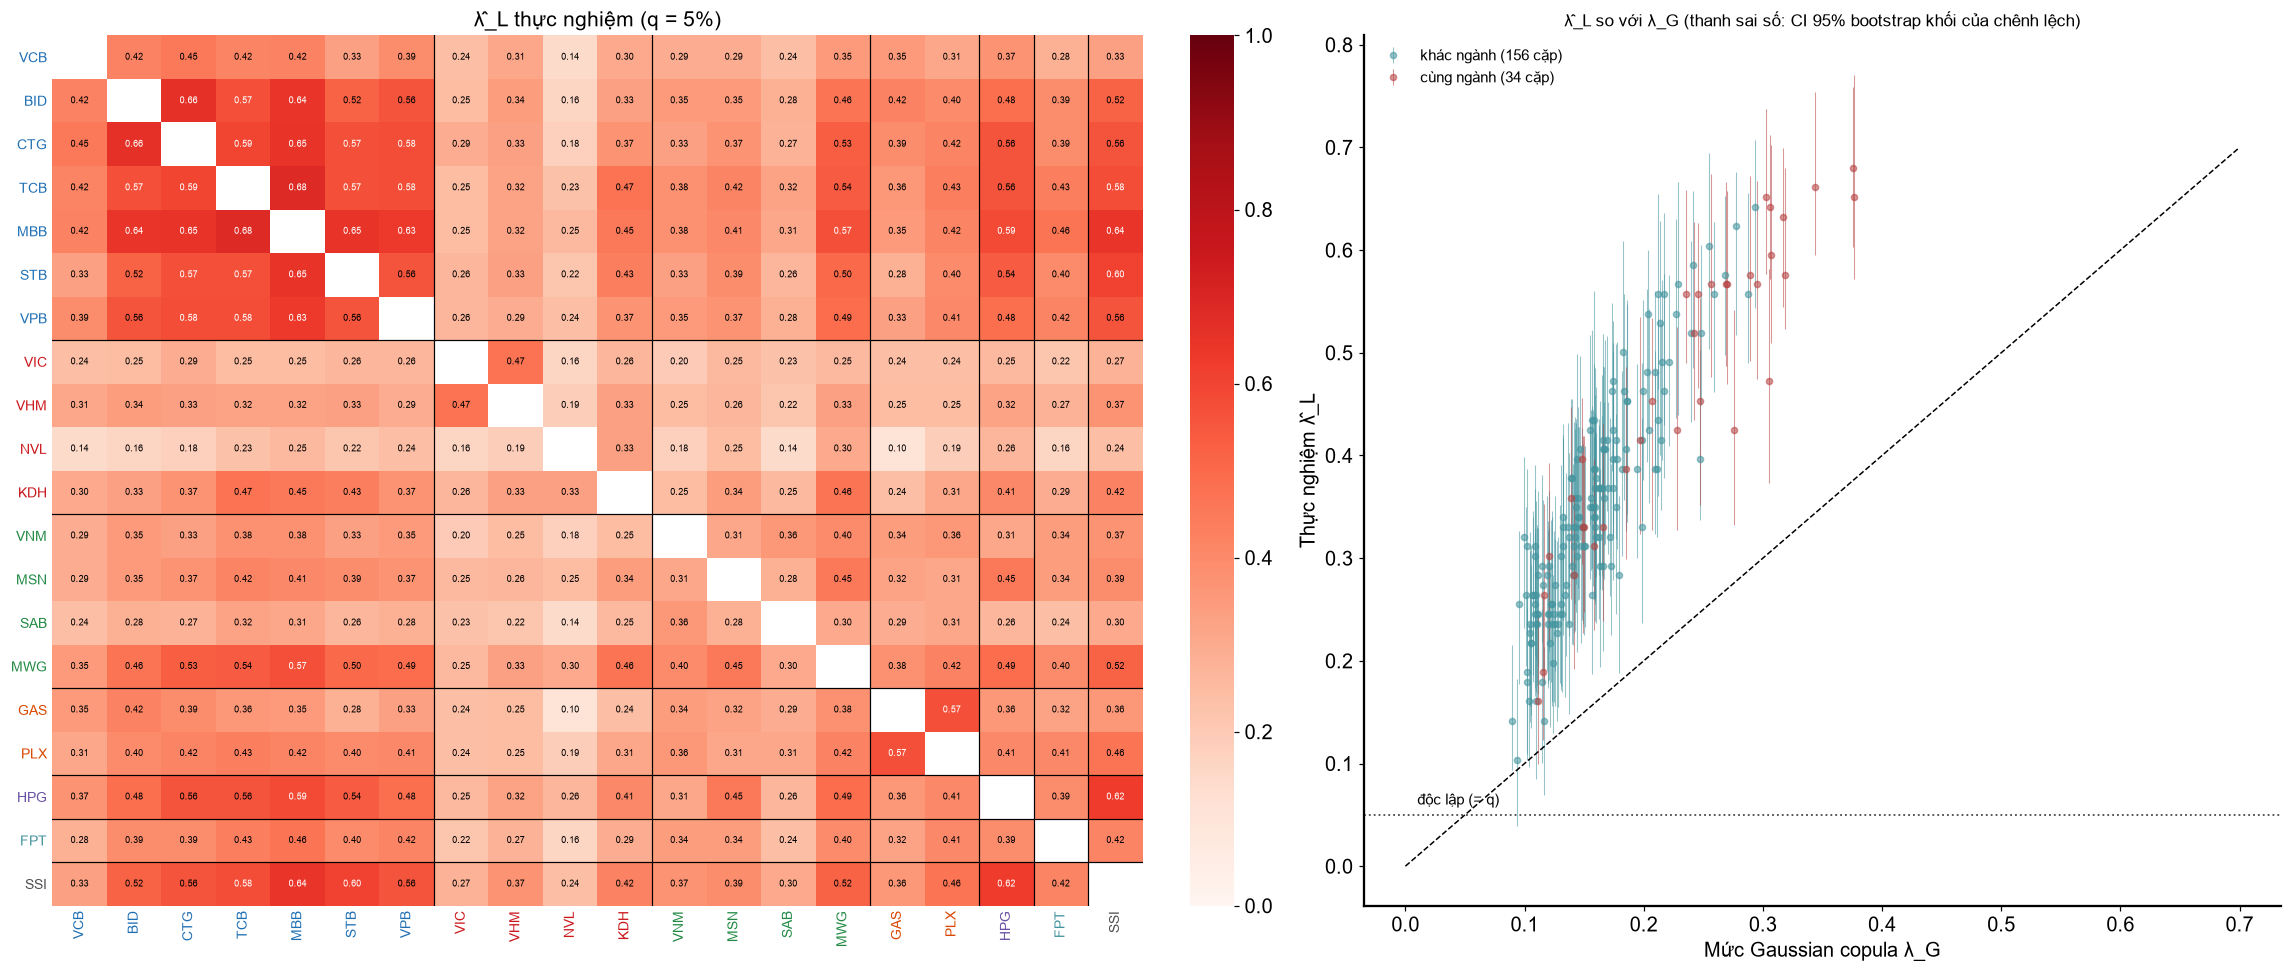

B = 1000, khối 20 phiên. λ̂_L TB 0.369 (độc lập = 0.05); λ_Gauss TB 0.171; tỷ số λ̂_L/λ_G: min 1.11 | TB 2.18 | max 3.23
Chênh lệch dương: 190/190; CI loại trừ 0: 184/190 (CI từng cặp, chưa hiệu chỉnh đa kiểm định)
cùng ngành: λ̂_L TB 0.466 | λ_G TB 0.233 | chênh lệch TB 0.234 | CI>0: 33/34
khác ngành: λ̂_L TB 0.348 | λ_G TB 0.157 | chênh lệch TB 0.191 | CI>0: 151/156


,λ̂_L,λ_Gauss,chênh lệch,"CI 2,5%","CI 97,5%",cùng ngành,CI loại trừ 0
TCB–MBB,0.6799,0.3758,0.3041,0.2276,0.3830,True,True
BID–CTG,0.6610,0.3441,0.3169,0.2515,0.4102,True,True
CTG–MBB,0.6516,0.3761,0.2754,0.1955,0.3944,True,True
MBB–STB,0.6516,0.3030,0.3486,0.2740,0.4348,True,True
MBB–SSI,0.6421,0.2936,0.3485,0.2503,0.4132,False,True
BID–MBB,0.6421,0.3063,0.3358,0.2658,0.4059,True,True
MBB–VPB,0.6327,0.3172,0.3154,0.2273,0.3820,True,True
HPG–SSI,0.6232,0.2770,0.3462,0.2402,0.3991,False,True


In [8]:
Q, BLOCK, B = 0.05, 20, 1000
zq = stats.norm.ppf(Q)
RH = np.linspace(-0.95, 0.99, 300)                      # λ_Gauss(ρ) tính sẵn trên lưới rồi nội suy (nhanh khi bootstrap 190 cặp)
LG = np.array([stats.multivariate_normal([0, 0], [[1, p], [p, 1]]).cdf([zq, zq]) for p in RH]) / Q

def tail_mats(x):
    n = len(x)
    ranks = rankdata(x, axis=0)
    ind = (ranks / (n + 1) <= Q).astype(float)
    lam = ind.T @ ind / (n * Q)
    rho = 2 * np.sin(np.pi / 6 * np.corrcoef(ranks.T))
    return lam, np.interp(rho, RH, LG)

lam_emp, lam_g = tail_mats(r.values)
rng = np.random.default_rng(42)
starts_all = np.arange(len(r) - BLOCK + 1)
boot = np.empty((B, len(pairs)))
for b in range(B):
    idx = (rng.choice(starts_all, size=int(np.ceil(len(r) / BLOCK)))[:, None] + np.arange(BLOCK)).ravel()[:len(r)]
    lb_, gb_ = tail_mats(r.values[idx])
    boot[b] = (lb_ - gb_)[iu]

tail = pd.DataFrame({"λ̂_L": lam_emp[iu], "λ_Gauss": lam_g[iu]}, index=pair_names)
tail["chênh lệch"] = tail["λ̂_L"] - tail["λ_Gauss"]
tail["CI 2,5%"] = np.percentile(boot, 2.5, axis=0)
tail["CI 97,5%"] = np.percentile(boot, 97.5, axis=0)
tail["cùng ngành"] = same_sector
tail["CI loại trừ 0"] = tail["CI 2,5%"] > 0

lamL = pd.DataFrame(lam_emp, index=SYMBOLS, columns=SYMBOLS).mask(np.eye(len(SYMBOLS), dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(21, 9), gridspec_kw={"width_ratios": [1.3, 1]})
big_heatmap(axes[0], lamL, fs_cell=6, cmap="Reds", vmin=0, vmax=1, title=f"λ̂_L thực nghiệm (q = {Q:.0%})")
ax = axes[1]
err = np.vstack([tail["chênh lệch"] - tail["CI 2,5%"], tail["CI 97,5%"] - tail["chênh lệch"]])
for flag, col, lab in [(False, PAL["teal"], "khác ngành"), (True, PAL["red_strong"], "cùng ngành")]:
    m = (tail["cùng ngành"] == flag).values
    ax.errorbar(tail["λ_Gauss"][m], tail["λ̂_L"][m], yerr=err[:, m], fmt="o", ms=4, color=col, ecolor=col, alpha=0.55,
                elinewidth=0.7, capsize=0, label=f"{lab} ({m.sum()} cặp)")
ax.plot([0, 0.7], [0, 0.7], color="black", ls="--", lw=1); ax.axhline(Q, color=PAL["gray_dark"], ls=":", lw=1.2)
ax.text(0.01, Q + 0.01, "độc lập (= q)", fontsize=10)
ax.set_xlabel("Mức Gaussian copula λ_G"); ax.set_ylabel("Thực nghiệm λ̂_L")
ax.set_title("λ̂_L so với λ_G (thanh sai số: CI 95% bootstrap khối của chênh lệch)", fontsize=11)
ax.legend(fontsize=10, loc="upper left")
U.finalize_figure(fig, "finding_7_lower_tail_dependence"); plt.show()
print(f"B = {B}, khối {BLOCK} phiên. λ̂_L TB {tail['λ̂_L'].mean():.3f} (độc lập = {Q}); λ_Gauss TB {tail['λ_Gauss'].mean():.3f}; tỷ số λ̂_L/λ_G: min %.2f | TB %.2f | max %.2f" % (
      (tail["λ̂_L"] / tail["λ_Gauss"]).min(), (tail["λ̂_L"] / tail["λ_Gauss"]).mean(), (tail["λ̂_L"] / tail["λ_Gauss"]).max()))
print(f"Chênh lệch dương: {(tail['chênh lệch'] > 0).sum()}/190; CI loại trừ 0: {int(tail['CI loại trừ 0'].sum())}/190 (CI từng cặp, chưa hiệu chỉnh đa kiểm định)")
for flag, lab in [(True, "cùng ngành"), (False, "khác ngành")]:
    d = tail[tail["cùng ngành"] == flag]
    print(f"{lab}: λ̂_L TB {d['λ̂_L'].mean():.3f} | λ_G TB {d['λ_Gauss'].mean():.3f} | chênh lệch TB {d['chênh lệch'].mean():.3f} | CI>0: {int(d['CI loại trừ 0'].sum())}/{len(d)}")
tail.sort_values("λ̂_L", ascending=False).head(8)

### Phân tích

- Với **cả 190/190 cặp**, xác suất cùng sập thực nghiệm $\hat\lambda_L$ cao hơn mức Gaussian copula dự đoán: trung bình **0,37 so với 0,17** (độc lập chỉ 0,05), tỷ số 1,1–3,2 lần, chênh lệch +0,01 đến +0,35.
  Cặp cùng ngành mạnh hơn: 0,47 so với 0,23 (khác ngành 0,35 so với 0,16). Mạnh nhất là nhóm ngân hàng và SSI: **TCB–MBB 0,68**, BID–CTG 0,66, CTG–MBB và MBB–STB 0,65, MBB–SSI 0,64 (khi một mã rơi vào 5% phiên tệ nhất, khoảng hai phần ba số lần mã kia cũng vậy).
- Khoảng tin cậy 95% (bootstrap khối, B = 1.000) của $\hat\lambda_L - \lambda_G$ loại trừ 0 ở **184/190 cặp** (từng cặp riêng lẻ, chưa hiệu chỉnh đa kiểm định). **Sáu cặp còn lại đều chứa NVL** (với VCB, BID, CTG, VIC, GAS, FPT): NVL–GAS có $\hat\lambda_L$ = 0,10 chỉ hơn Gaussian 0,09 một chút
  → NVL có phụ thuộc đuôi gần như Gaussian với phần còn lại của thị trường (phù hợp với rủi ro riêng của NVL).
- Hệ quả: tương quan tuyến tính **đánh giá thấp rủi ro cùng sập**. Mô hình phụ thuộc nên dùng copula có phụ thuộc đuôi (Student-t, Clayton) hoặc phương pháp dành cho đuôi — rất sát với hướng *causal discovery in heavy-tailed models* của đồ án.

## Phát hiện 8 — Không có quan hệ dẫn–trễ (Granger) nào vượt hiệu chỉnh đa kiểm định

**Tính gì:** với mỗi cặp có hướng $a \to b$ (380 cặp), kiểm tra lợi suất quá khứ của $a$ có giúp dự báo lợi suất của $b$ hay không,
ngoài phần mà quá khứ của chính $b$ đã giải thích.

**Công thức.** Hồi quy với số độ trễ chọn trước $p = 5$ (một tuần giao dịch):
$$r_{b,t} = c + \sum_{k=1}^{p}\beta_k\, r_{b,t-k} + \sum_{k=1}^{p}\gamma_k\, r_{a,t-k} + \varepsilon_t .$$
"$a$ Granger-gây ra $b$" khi bác bỏ $H_0: \gamma_1 = \dots = \gamma_p = 0$, bằng thống kê Wald
$W = \hat{\boldsymbol\gamma}^\top\big[\widehat{\text{Var}}(\hat{\boldsymbol\gamma})\big]^{-1}\hat{\boldsymbol\gamma} \sim \chi^2_p$.

- $\widehat{\text{Var}}$ dùng ước lượng **HAC Newey–West** (10 độ trễ) — chịu được phương sai thay đổi theo thời gian (Phát hiện 5) và tự tương quan;
  F-test thông thường sẽ sai khi có hiệu ứng ARCH.
- 380 kiểm định cùng lúc → hiệu chỉnh **Bonferroni**: chỉ coi là có ý nghĩa khi $p < 0{,}05/380 \approx 1{,}3\times10^{-4}$; kèm hiệu chỉnh **Holm**. Nếu mọi $H_0$ đúng, kỳ vọng ≈ 19 cặp có $p < 0{,}05$ chỉ do ngẫu nhiên.

**Các bước:** (1) tạo 5 cột trễ cho mỗi mã; (2) với mỗi cặp, ước lượng OLS với sai số HAC; (3) kiểm định Wald;
(4) vẽ heatmap $-\log_{10}(p)$ 20×20 và đồ thị Q–Q của 380 giá trị $p$ so với phân phối đều (nếu không có quan hệ dẫn–trễ, $p$ phân phối đều).

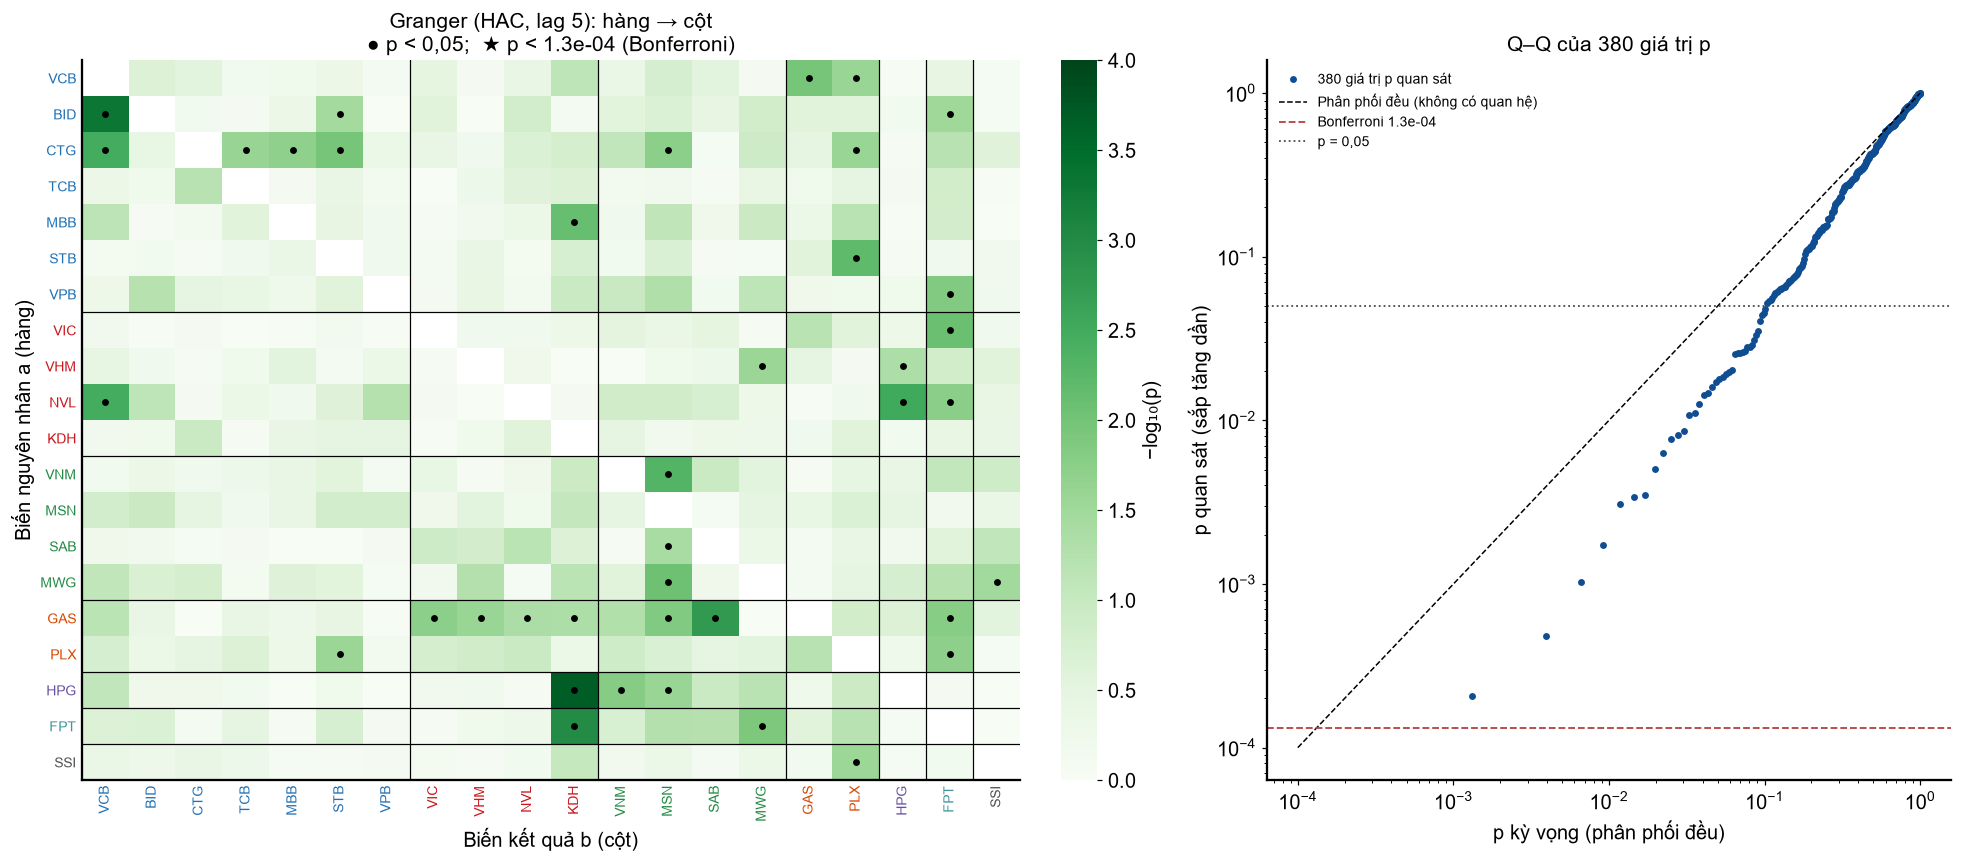

380 kiểm định | p < 0,05: 39 (10.3%; kỳ vọng ngẫu nhiên 5%) | Bonferroni: 0 | Holm: 0
Tỷ lệ p < 0,05: cùng ngành 0.132 | khác ngành 0.096
p nhỏ nhất: [['HPG→KDH', 0.00021, 0.07875], ['BID→VCB', 0.00048, 0.18111], ['FPT→KDH', 0.00103, 0.38773], ['GAS→SAB', 0.00173, 0.65035], ['NVL→HPG', 0.00307, 1.0]]


,Wald χ²(5),p (HAC),p Holm
cặp,,,
HPG→KDH,24.1051,0.0002,0.0788
BID→VCB,22.2086,0.0005,0.1811
FPT→KDH,20.4564,0.0010,0.3877
GAS→SAB,19.2520,0.0017,0.6504
NVL→HPG,17.9001,0.0031,1.0000
NVL→VCB,17.6774,0.0034,1.0000
CTG→VCB,17.5860,0.0035,1.0000
VNM→MSN,16.7313,0.0050,1.0000


In [9]:
LAG = 5
lagged = {s: pd.concat({f"{s}_l{k}": r[s].shift(k) for k in range(1, LAG + 1)}, axis=1) for s in SYMBOLS}
rows = []
for a in SYMBOLS:
    for b in SYMBOLS:
        if a == b:
            continue
        X = sm.add_constant(pd.concat([lagged[b], lagged[a]], axis=1)).dropna()
        fit = sm.OLS(r[b].loc[X.index], X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        w = fit.wald_test(" = 0, ".join(lagged[a].columns) + " = 0", scalar=True)
        rows.append({"nguyên nhân": a, "kết quả": b, "cặp": f"{a}→{b}", "Wald χ²(5)": w.statistic, "p (HAC)": w.pvalue})
granger = pd.DataFrame(rows)
BONF = 0.05 / len(granger)
granger["p Holm"] = multipletests(granger["p (HAC)"], method="holm")[1]
granger["cùng ngành"] = [SECTOR[a] == SECTOR[b] for a, b in zip(granger["nguyên nhân"], granger["kết quả"])]
pmat = granger.pivot(index="nguyên nhân", columns="kết quả", values="p (HAC)").loc[SYMBOLS, SYMBOLS]

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
im = ax.imshow(-np.log10(pmat.values), cmap="Greens", vmin=0, vmax=4, aspect="auto")
for i in range(len(SYMBOLS)):
    for j in range(len(SYMBOLS)):
        p = pmat.values[i, j]
        if np.isnan(p): continue
        if p < BONF: ax.plot(j, i, marker="*", ms=11, color=PAL["red_strong"], mec="black", mew=0.4)
        elif p < 0.05: ax.plot(j, i, marker="o", ms=3.5, color="black")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("−log₁₀(p)"); cb.outline.set_visible(False)
ax.tick_params(length=0); sector_style(ax, SYMBOLS)
ax.set_xlabel("Biến kết quả b (cột)"); ax.set_ylabel("Biến nguyên nhân a (hàng)")
ax.set_title(f"Granger (HAC, lag {LAG}): hàng → cột\n● p < 0,05;  ★ p < {BONF:.1e} (Bonferroni)")
p_sorted = np.sort(granger["p (HAC)"].values)
expected = (np.arange(1, len(p_sorted) + 1) - 0.5) / len(p_sorted)
axes[1].loglog(expected, p_sorted, "o", ms=3.5, color=PAL["blue_main"], label="380 giá trị p quan sát")
axes[1].plot([1e-4, 1], [1e-4, 1], color="black", ls="--", lw=1, label="Phân phối đều (không có quan hệ)")
axes[1].axhline(BONF, color=PAL["red_strong"], ls="--", lw=1.2, label=f"Bonferroni {BONF:.1e}")
axes[1].axhline(0.05, color=PAL["gray_dark"], ls=":", lw=1.2, label="p = 0,05")
axes[1].set_xlabel("p kỳ vọng (phân phối đều)"); axes[1].set_ylabel("p quan sát (sắp tăng dần)")
axes[1].set_title("Q–Q của 380 giá trị p"); axes[1].legend(fontsize=9, loc="upper left")
U.finalize_figure(fig, "finding_8_granger"); plt.show()
n05 = int((granger["p (HAC)"] < 0.05).sum())
print(f"{len(granger)} kiểm định | p < 0,05: {n05} ({n05/len(granger):.1%}; kỳ vọng ngẫu nhiên 5%) | Bonferroni: {int((granger['p (HAC)'] < BONF).sum())} | Holm: {int((granger['p Holm'] < 0.05).sum())}")
print("Tỷ lệ p < 0,05: cùng ngành %.3f | khác ngành %.3f" % tuple(granger.groupby("cùng ngành")["p (HAC)"].apply(lambda p: (p < .05).mean()).reindex([True, False])))
print("p nhỏ nhất:", granger.sort_values("p (HAC)").head(5)[["cặp", "p (HAC)", "p Holm"]].round(5).values.tolist())
granger.sort_values("p (HAC)").set_index("cặp")[["Wald χ²(5)", "p (HAC)", "p Holm"]].head(8)

### Phân tích

- **Không cặp nào** vượt ngưỡng Bonferroni ($p < 1{,}3\times10^{-4}$) hay Holm trong 380 kiểm định. Nhỏ nhất là **HPG→KDH (p = 2,1·10⁻⁴; Holm 0,079)**, rồi BID→VCB (4,8·10⁻⁴; Holm 0,18), FPT→KDH (1,0·10⁻³), GAS→SAB (1,7·10⁻³), NVL→HPG (3,1·10⁻³).
- Có **39/380 cặp (10,3%) có $p < 0{,}05$**, gấp ~2 lần kỳ vọng ngẫu nhiên (≈ 19 cặp, 5%); đồ thị Q–Q của các giá trị $p$ nằm lệch về phía $p$ nhỏ trong vùng 10⁻³–10⁻¹, tức là có thể có **quan hệ dẫn–trễ yếu rải rác** nhưng không cặp nào đủ mạnh để loại trừ ngẫu nhiên sau khi hiệu chỉnh.
  Dấu hiệu tập trung: GAS "dẫn" 7 cặp có $p < 0{,}05$ (tới VIC, VHM, NVL, KDH, MSN, SAB, FPT), CTG 6 cặp; FPT và MSN là biến kết quả của 6 cặp mỗi mã. Tỷ lệ $p < 0{,}05$ ở cặp cùng ngành 13,2%, khác ngành 9,6%.
- Hệ quả: ở tần suất ngày, **chưa có bằng chứng đủ mạnh** rằng lợi suất quá khứ của mã này dự báo được mã kia (tương quan trễ 1 phiên |ρ| ≤ 0,11). Quan hệ giữa các mã chủ yếu là **đồng thời** (cùng phiên) — phương pháp nhân quả cần khai thác cấu trúc đồng thời
  (ví dụ mô hình phương trình cấu trúc với nhiễu không chuẩn / đuôi dày) thay vì chỉ dựa vào độ trễ thời gian. Các cặp có $p < 0{,}05$ nên kiểm tra lại sau khi lọc GARCH và kiểm soát nhân tố thị trường.

## Phát hiện 9 — Khối lượng giao dịch tăng thì biến động tăng

**Tính gì:** quan hệ giữa khối lượng tương đối và độ lớn lợi suất trong cùng phiên.

**Công thức.**

- Khối lượng tương đối: $RV_{i,t} = V_{i,t} \Big/ \frac{1}{20}\sum_{k=1}^{20} V_{i,t-k}$ — khối lượng hôm nay so với trung bình 20 phiên **trước đó**
  ($RV > 1$: giao dịch sôi động bất thường). Cột `rel_volume` trong CSDL.
- Tương quan hạng Spearman giữa $\ln RV_{i,t}$ và $|r_{i,t}|$: $\rho_S = 1 - \dfrac{6\sum_t d_t^2}{T(T^2-1)}$, $d_t$ là chênh lệch hạng —
  đo quan hệ đơn điệu, không đòi hỏi tuyến tính và ít nhạy với giá trị ngoại lai.
- Trung bình theo nhóm thập phân vị (decile): chia các phiên thành 10 nhóm bằng nhau theo $\ln RV$, tính $\overline{|r|}$ trong từng nhóm.

**Các bước:** (1) lấy `rel_volume` và `log_ret` trong khung phân tích; (2) tính $\rho_S$ cho từng mã;
(3) tính $\overline{|r|}$ theo decile của $\ln RV$ và vẽ đường cho từng mã.

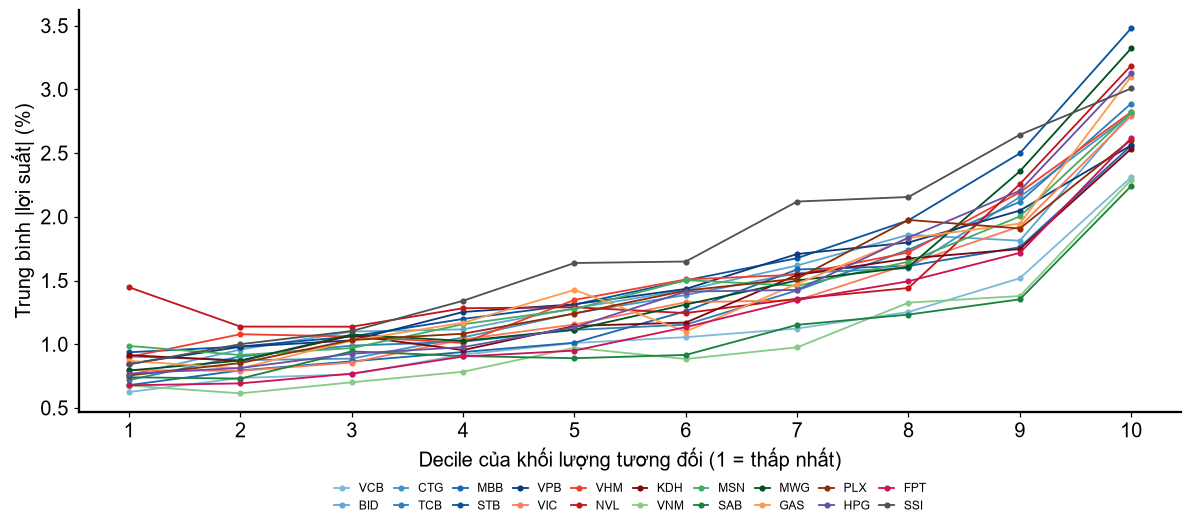

Spearman ρ_S: min 0.23 (NVL) | max 0.44 (HPG) | TB 0.34 | p < 0,001: 20/20 | tỷ số D10/D1: min 2.2 | max 4.2


,ngành,Spearman ρ_S,p-value,|r| decile 1 (%),|r| decile 10 (%),tỷ số D10/D1
symbol,,,,,,
VCB,Ngân hàng,0.3157,0.0000,0.6247,2.3111,3.6996
BID,Ngân hàng,0.3429,0.0000,0.7585,2.8172,3.7144
CTG,Ngân hàng,0.3431,0.0000,0.9036,2.8061,3.1056
TCB,Ngân hàng,0.3878,0.0000,0.7192,2.8890,4.0172
MBB,Ngân hàng,0.3681,0.0000,0.6791,2.5585,3.7677
STB,Ngân hàng,0.4068,0.0000,0.9367,3.4798,3.7148
VPB,Ngân hàng,0.3111,0.0000,0.8462,2.5613,3.0267
VIC,Bất động sản,0.2828,0.0000,0.7966,2.7929,3.5063
VHM,Bất động sản,0.2828,0.0000,0.8999,2.8216,3.1354


In [10]:
vv = con.execute("SELECT symbol, ABS(log_ret) AS abs_r, LN(rel_volume) AS ln_rv FROM v_analysis WHERE rel_volume > 0").df()
rows = []
fig, ax = plt.subplots(figsize=(11, 5))
for s in SYMBOLS:
    d = vv[vv.symbol == s].copy()
    d["decile"] = pd.qcut(d.ln_rv, 10, labels=range(1, 11))
    m = d.groupby("decile", observed=True).abs_r.mean()
    ax.plot(m.index.astype(int), 100 * m.values, marker="o", ms=3, lw=1.2, color=COL[s], label=s)
    rho = stats.spearmanr(d.ln_rv, d.abs_r)
    rows.append({"symbol": s, "ngành": SECTOR[s], "Spearman ρ_S": rho.statistic, "p-value": rho.pvalue,
                 "|r| decile 1 (%)": 100 * m.iloc[0], "|r| decile 10 (%)": 100 * m.iloc[-1], "tỷ số D10/D1": m.iloc[-1] / m.iloc[0]})
ax.set_xticks(range(1, 11)); ax.set_xlabel("Decile của khối lượng tương đối (1 = thấp nhất)")
ax.set_ylabel("Trung bình |lợi suất| (%)")
ax.legend(ncol=10, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), columnspacing=0.8, handlelength=1.2)
U.finalize_figure(fig, "finding_9_volume_volatility"); plt.show()
vv_tab = pd.DataFrame(rows).set_index("symbol")
print("Spearman ρ_S: min %.2f (%s) | max %.2f (%s) | TB %.2f | p < 0,001: %d/20 | tỷ số D10/D1: min %.1f | max %.1f" % (
    vv_tab["Spearman ρ_S"].min(), vv_tab["Spearman ρ_S"].idxmin(), vv_tab["Spearman ρ_S"].max(), vv_tab["Spearman ρ_S"].idxmax(),
    vv_tab["Spearman ρ_S"].mean(), (vv_tab["p-value"] < 1e-3).sum(), vv_tab["tỷ số D10/D1"].min(), vv_tab["tỷ số D10/D1"].max()))
vv_tab

### Phân tích

- Ở cả 20 mã, $|r|$ trung bình tăng theo decile khối lượng tương đối: từ decile thấp nhất đến cao nhất tăng **2,2 lần (NVL) đến 4,2 lần (MWG)** (HPG 4,1; TCB 4,0); Spearman $\rho_S = 0{,}23$–$0{,}44$ (trung bình 0,34), p < 0,001 ở 20/20 mã; mạnh nhất HPG (0,44), MWG (0,43), STB và FPT (0,41), yếu nhất NVL (0,23), SAB (0,27), VIC và VHM (0,28).
  Theo ngành: thép 0,44, công nghệ 0,41, chứng khoán 0,36, ngân hàng 0,35, tiêu dùng 0,35, năng lượng 0,33, bất động sản 0,27 (thấp nhất).
- Quan hệ **không hoàn toàn đơn điệu** ở đầu thấp: decile 1 của NVL có $|r|$ = 1,45% — cao nhất trong 20 mã và cao hơn các decile kế tiếp. Một giả thuyết (chưa kiểm chứng) là các phiên giảm sàn liên tiếp cuối 2022 của NVL có khối lượng khớp rất thấp nhưng |r| lớn.
- Hệ quả: khối lượng mang thông tin về biến động cùng phiên (phù hợp giả thuyết phân phối hỗn hợp); có thể đưa khối lượng vào mô hình biến động (GARCH-X) hoặc làm biến điều kiện. Lưu ý phiên sàn/trần khối lượng thấp làm méo quan hệ này.

## Phát hiện 10 — Khác biệt giữa các ngành và giữa 5 mã gốc với 15 mã mới

**Tính gì:** so sánh giữa 7 ngành (và giữa 5 mã gốc VHM, NVL, STB, VPB, HPG với 15 mã mới) về lợi suất, biến động, MDD, độ nhọn, mức bị chặn biên, hệ số tải PC1, tương quan và phụ thuộc đuôi dưới.

**Công thức.** Mọi chỉ số đã định nghĩa ở Phát hiện 2–7, ở đây lấy **trung bình theo nhóm**: $\bar x_G = \frac{1}{|G|}\sum_{i\in G}x_i$ cho chỉ số theo mã ($\mu$, $\sigma$, MDD, $K$, tỷ lệ phiên chạm trần/sàn, hệ số tải PC1);
$\bar\rho_G = \frac{1}{|P_G|}\sum_{(i,j)\in P_G}\rho_{ij}$ và $\bar\lambda_{L,G}$ tương tự cho chỉ số theo cặp, trong đó $P_G$ là tập các cặp có cả hai mã thuộc nhóm $G$ (ngành có 1 mã không có cặp nên để trống).

**Các bước:** (1) gom bảng theo ngành và theo nhóm gốc/mới; (2) tính trung bình cặp trong ngành, trong nhóm và chéo giữa hai nhóm; (3) vẽ cột biến động và |MDD| theo ngành, cùng heatmap $\bar\lambda_L$ giữa từng cặp ngành.
**Lưu ý:** ngành chỉ có 1–2 mã (thép, công nghệ, chứng khoán, năng lượng) nên số liệu trung bình ngành chỉ mang tính mô tả; nhóm "gốc" gồm 2/4 mã bất động sản, 2/7 mã ngân hàng và HPG, nên so sánh gốc–mới bị trộn với hiệu ứng ngành.

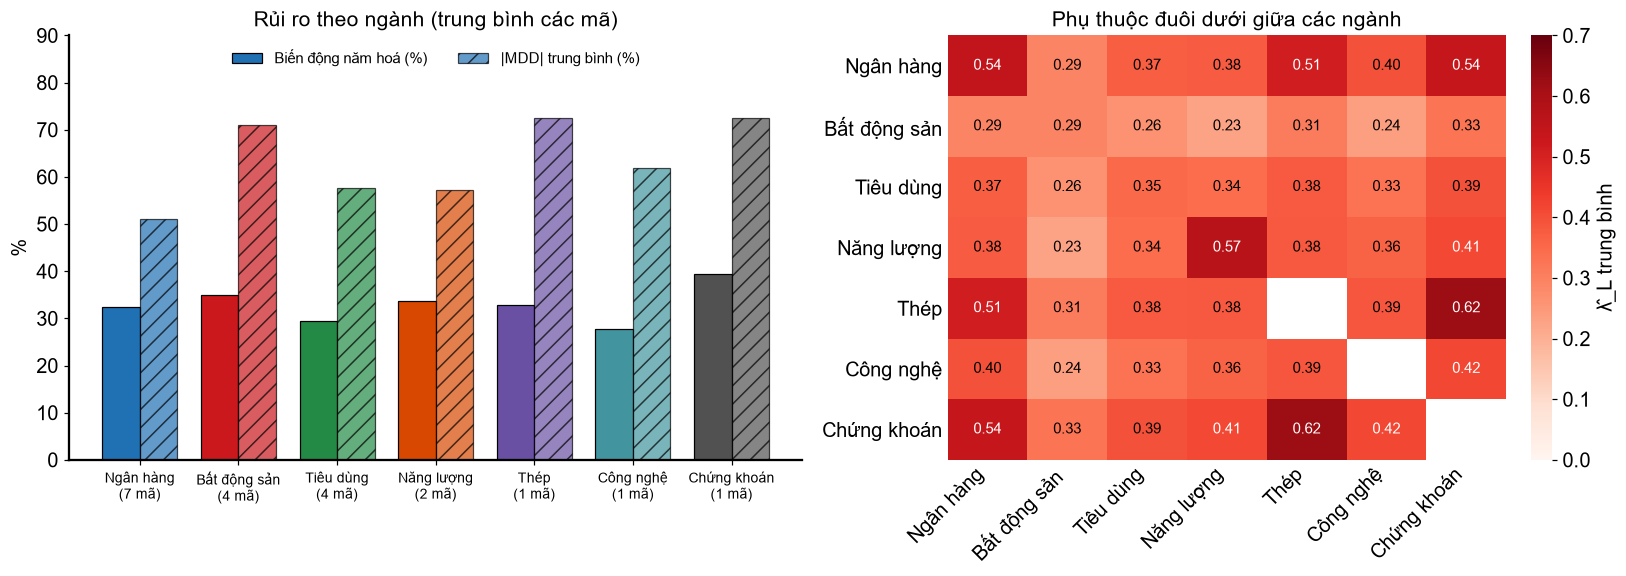

,số mã,mu_nam (%),sigma_nam (%),MDD TB (%),K TB,% phiên chạm biên,PC1 TB,ρ trong ngành,λ̂_L trong ngành
ngành,,,,,,,,,
Ngân hàng,7,11.5410,32.3290,-51.1310,2.4930,2.1300,0.2570,0.5890,0.5450
Bất động sản,4,4.4120,34.9780,-71.0620,2.4670,3.2780,0.1640,0.3330,0.2910
Tiêu dùng,4,0.0880,29.5020,-57.7030,3.0380,1.5450,0.1950,0.3420,0.3510
Năng lượng,2,-0.4570,33.7180,-57.2750,2.4240,2.4530,0.1980,0.6440,0.5670
Thép,1,8.1000,32.7690,-72.4490,2.0480,1.6040,0.2440,NaN,NaN
Công nghệ,1,14.9840,27.8210,-61.8870,2.8540,1.0380,0.2350,NaN,NaN
Chứng khoán,1,10.2720,39.4660,-72.4840,1.5390,4.5280,0.2660,NaN,NaN


,số mã,mu_nam (%),sigma_nam (%),MDD TB (%),K TB,% phiên chạm biên,PC1 TB,ρ trong nhóm,λ̂_L trong nhóm
nhóm,,,,,,,,,
gốc,5.0000,6.9700,35.4560,-66.3510,2.0580,3.2080,0.2100,0.3480,0.3430
mới,15.0000,6.4250,31.6290,-57.5060,2.6980,2.0160,0.2220,0.3970,0.3770
chéo (gốc–mới),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3740,0.3630


In [11]:
GROUP = {s: ("gốc" if s in ORIG else "mới") for s in SYMBOLS}
kurt = shape["K (độ nhọn vượt chuẩn)"]
box = (hits.ty_le_tran + hits.ty_le_san)                       # tỷ lệ phiên chạm trần hoặc sàn
base = pd.DataFrame({"ngành": [SECTOR[s] for s in SYMBOLS], "nhóm": [GROUP[s] for s in SYMBOLS],
                     "mu_nam": summary.mu_nam, "sigma_nam": summary.sigma_nam, "MDD": summary.MDD,
                     "K": kurt, "chạm biên": box, "PC1": loadings["PC1"]}, index=SYMBOLS)
corr_s = pd.Series(R.values[iu], index=pair_names)
def grp_pairs(mask_fn):
    return np.array([mask_fn(a, b) for a, b in pairs])
rows = []
for sec in SECTORS:
    m = [s for s in SYMBOLS if SECTOR[s] == sec]
    inside = grp_pairs(lambda a, b: SECTOR[a] == sec and SECTOR[b] == sec)
    rows.append({"ngành": sec, "số mã": len(m), "mu_nam (%)": 100 * base.loc[m, "mu_nam"].mean(),
                 "sigma_nam (%)": 100 * base.loc[m, "sigma_nam"].mean(), "MDD TB (%)": 100 * base.loc[m, "MDD"].mean(),
                 "K TB": base.loc[m, "K"].mean(), "% phiên chạm biên": 100 * base.loc[m, "chạm biên"].mean(),
                 "PC1 TB": base.loc[m, "PC1"].mean(),
                 "ρ trong ngành": corr_s[inside].mean() if inside.any() else np.nan,
                 "λ̂_L trong ngành": tail["λ̂_L"][inside].mean() if inside.any() else np.nan})
by_sector = pd.DataFrame(rows).set_index("ngành")
U.save_table(by_sector, "finding_10_by_sector", folder="eda")

rows = []
for g in ("gốc", "mới"):
    m = [s for s in SYMBOLS if GROUP[s] == g]
    inside = grp_pairs(lambda a, b: GROUP[a] == g and GROUP[b] == g)
    rows.append({"nhóm": g, "số mã": len(m), "mu_nam (%)": 100 * base.loc[m, "mu_nam"].mean(),
                 "sigma_nam (%)": 100 * base.loc[m, "sigma_nam"].mean(), "MDD TB (%)": 100 * base.loc[m, "MDD"].mean(),
                 "K TB": base.loc[m, "K"].mean(), "% phiên chạm biên": 100 * base.loc[m, "chạm biên"].mean(),
                 "PC1 TB": base.loc[m, "PC1"].mean(), "ρ trong nhóm": corr_s[inside].mean(), "λ̂_L trong nhóm": tail["λ̂_L"][inside].mean()})
cross = grp_pairs(lambda a, b: GROUP[a] != GROUP[b])
by_group = pd.DataFrame(rows).set_index("nhóm")
by_group.loc["chéo (gốc–mới)", ["ρ trong nhóm", "λ̂_L trong nhóm"]] = [corr_s[cross].mean(), tail["λ̂_L"][cross].mean()]
U.save_table(by_group, "finding_10_by_group", folder="eda")

# λ̂_L trung bình giữa các cặp ngành
lam_sec = pd.DataFrame(np.nan, index=SECTORS, columns=SECTORS)
for sa in SECTORS:
    for sb in SECTORS:
        ma, mb = [s for s in SYMBOLS if SECTOR[s] == sa], [s for s in SYMBOLS if SECTOR[s] == sb]
        blk = lamL.loc[ma, mb].values
        v = blk[~np.isnan(blk)]
        if v.size: lam_sec.loc[sa, sb] = v.mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.2, 1]})
xx = np.arange(len(SECTORS)); wd = 0.38
axes[0].bar(xx - wd / 2, 100 * by_sector["sigma_nam (%)"] / 100, wd, color=[SC[s] for s in SECTORS], edgecolor="black", lw=0.8, label="Biến động năm hoá (%)")
axes[0].bar(xx + wd / 2, -by_sector["MDD TB (%)"], wd, color=[SC[s] for s in SECTORS], edgecolor="black", lw=0.8, hatch="//", alpha=0.7, label="|MDD| trung bình (%)")
axes[0].set_xticks(xx, [f"{s}\n({int(by_sector.loc[s, 'số mã'])} mã)" for s in SECTORS], fontsize=9)
axes[0].set_ylabel("%"); axes[0].set_title("Rủi ro theo ngành (trung bình các mã)"); axes[0].set_ylim(0, 90); axes[0].legend(fontsize=10, loc="upper center", ncol=2)
U.make_heatmap(axes[1], lam_sec, cmap="Reds", vmin=0, vmax=0.7, cbar_label="λ̂_L trung bình", title="Phụ thuộc đuôi dưới giữa các ngành")
axes[1].set_xticks(range(len(SECTORS)), SECTORS, rotation=45, ha="right")
U.finalize_figure(fig, "finding_10_sectors"); plt.show()
display(by_sector.round(3)); by_group.round(3)

### Phân tích

**Theo ngành** (trung bình các mã; ngành 1–2 mã chỉ mang tính mô tả):

- **Rủi ro:** biến động năm hoá cao nhất ở chứng khoán (SSI 39,5%), rồi bất động sản (35,0%), năng lượng (33,7%), thép (32,8%), ngân hàng (32,3%); thấp nhất tiêu dùng (29,5%) và công nghệ (27,8%). MDD trung bình nặng nhất ở **thép (−72,4%), chứng khoán (−72,5%) và bất động sản (−71,1%)**, nhẹ nhất ở ngân hàng (−51,1%).
- **Lợi suất:** công nghệ +15,0%/năm, ngân hàng +11,5%, chứng khoán +10,3%, thép +8,1%, bất động sản +4,4%, tiêu dùng +0,1%, năng lượng −0,5%. Hai ngành phòng thủ (tiêu dùng, năng lượng) vừa đi ngang vừa có độ nhọn cao nhất (tiêu dùng K = 3,04) — nhiều phiên êm, ít cú sốc lớn.
- **Mức bị chặn biên** (tỷ lệ phiên chạm trần + sàn): chứng khoán 4,5%, bất động sản 3,3%, năng lượng 2,5%, ngân hàng 2,1%, thép 1,6%, tiêu dùng 1,5%, công nghệ 1,0% → ước lượng đuôi nhạy với việc chọn ngành.
- **Gắn kết:** ngành gắn kết nhất là **năng lượng (ρ trong ngành 0,64; $\bar\lambda_L$ 0,57)** và **ngân hàng (0,59; 0,55)**; tiêu dùng (0,34; 0,35) và **bất động sản (0,33; 0,29) gắn kết yếu**. Giữa các ngành, cao nhất là thép–chứng khoán ($\bar\lambda_L$ = 0,62), ngân hàng–chứng khoán (0,54) và ngân hàng–thép (0,51);
  bất động sản có phụ thuộc đuôi thấp nhất với mọi ngành khác (0,23–0,33) — nhất quán với PC2 (nhân tố Vingroup/bất động sản) và với vai trò ngoại lệ của NVL. Hệ số tải PC1 (nhân tố thị trường) lớn nhất ở chứng khoán (0,27) và ngân hàng (0,26), nhỏ nhất ở bất động sản (0,16).

**5 mã gốc so với 15 mã mới:**

- Nhóm gốc có **biến động cao hơn (35,5% so với 31,6%), MDD nặng hơn (−66,4% so với −57,5%), bị chặn biên nhiều hơn (3,2% so với 2,0% số phiên)** nhưng độ nhọn thấp hơn (K = 2,06 so với 2,70); lợi suất trung bình tương đương (7,0% so với 6,4%/năm).
  Nhóm mới gồm nhiều mã vốn hoá lớn, ổn định (VCB, VNM, SAB, FPT) nên có ít phiên chạm biên nhưng nhiều cú sốc hiếm (độ nhọn cao).
- Mức phụ thuộc: tương quan trung bình trong nhóm gốc 0,35, trong nhóm mới 0,40, chéo gốc–mới 0,37; $\bar\lambda_L$ tương ứng 0,34 / 0,38 / 0,36. Nhóm gốc **kém gắn kết hơn** nhóm mới do chứa 2 mã bất động sản (VHM, NVL) — ngành gắn kết yếu nhất — chứ không phải vì khác biệt bản chất giữa hai nhóm; kết luận gốc–mới do đó bị trộn với hiệu ứng ngành.
- Tóm lại các phát hiện chính của mẫu 5 mã (đuôi dày, bị chặn ±7%, biến động cụm, nhân tố thị trường, phụ thuộc đuôi mạnh hơn Gaussian, Granger không có ý nghĩa sau hiệu chỉnh, khối lượng–biến động) **đều giữ nguyên** khi mở rộng lên 20 mã; điều thay đổi là cấu trúc ngành rõ hơn (PC2, PC3) và NVL nổi bật là ngoại lệ trên mọi chỉ số.

## Tổng kết — từ phát hiện đến lựa chọn mô hình

### Phân tích

| # | Phát hiện | Bằng chứng chính (20 mã) | Hệ quả cho bước mô hình hoá |
|---|---|---|---|
| 1 | VHM trước 17/05/2018 là giá ảo; TCB niêm yết 04/06/2018 | 629 phiên giá đứng; lợi suất ảo +268% | Khung chung 01/06/2018 → 25/11/2026 (T = 2.118 phiên chung) |
| 2 | Lợi suất khác biệt, biến động tương tự | VIC +20,4%, STB +20,3%; NVL −12,3%, MDD −91,2%; σ 24–39,5% | Xử lý NVL như trường hợp đặc biệt khi diễn giải |
| 3 | Không chuẩn, đuôi dày | K = 1,5–3,9; JB p ≈ 0 (20/20); 5,6–12,6% phiên đứng giá | Bỏ giả định chuẩn; cẩn trọng với khối xác suất tại 0 |
| 4 | Đuôi bị chặn ±7% | ~410 phiên dồn tại mỗi biên; chạm trần 0,28–2,31%, chạm sàn 0,33–2,45%; Hill chỉ hội tụ ở k ≥ 80–100 | EVT có kiểm duyệt hoặc lợi suất tuần |
| 5 | Biến động cụm | $\hat\rho_{|r|}(1)$ = 0,14–0,37; Q(10) của $r^2$: p ≈ 0 (20/20); đỉnh chung 67% (06/04/2020) | Lọc GARCH / sai số HAC trước phân tích phụ thuộc |
| 6 | Nhân tố thị trường + nhân tố ngành | PC1 43%; PC2 Vingroup/BĐS (6,8%); PC3 năng lượng–tiêu dùng (6,1%); 3 trị riêng > ngưỡng nhiễu | Kiểm soát nhân tố chung và nhân tố ngành khi suy luận nhân quả |
| 7 | Phụ thuộc đuôi dưới > Gaussian | $\hat\lambda_L$ = 0,37 so với $\lambda_G$ = 0,17; 190/190 cặp dương, CI > 0 ở 184 cặp (6 cặp còn lại chứa NVL) | Copula đuôi (t, Clayton), phương pháp nhân quả cho đuôi dày |
| 8 | Không có dẫn–trễ vượt hiệu chỉnh | 39/380 cặp p < 0,05 (kỳ vọng 19), 0 cặp qua Bonferroni/Holm (nhỏ nhất HPG→KDH, p = 2,1·10⁻⁴) | Tập trung vào quan hệ đồng thời; kiểm tra lại sau lọc GARCH |
| 9 | Khối lượng ↔ biến động | $\rho_S$ = 0,23–0,44 (20/20 có p < 0,001); decile cao gấp 2,2–4,2 lần | Khối lượng là biến giải thích cho biến động |
| 10 | Khác biệt ngành; gốc so với mới | Gắn kết cao nhất: năng lượng, ngân hàng; thấp nhất: bất động sản. Nhóm gốc σ 35,5% / MDD −66% so với nhóm mới 31,6% / −58% | Diễn giải theo ngành; so sánh cũ – mới phải tính tới cơ cấu ngành |

**Thứ tự đề xuất cho bước tiếp theo:** (1) lọc GARCH-t cho từng mã → phần dư chuẩn hoá; (2) xử lý quan sát trần/sàn như dữ liệu
kiểm duyệt (hoặc chuyển sang lợi suất tuần) trước khi ước lượng đuôi; (3) mô hình hoá phụ thuộc đồng thời và phụ thuộc đuôi
trên phần dư, có kiểm soát nhân tố thị trường và nhân tố ngành.